
Loading sst: data\era5\era5_global\era5_sea_surface_temperature_1940_2025.nc
Loaded shape: (1032, 20, 80)
SST: EOF1 variance = 49.99%
  Original r=+0.966, aligned r=+0.966, flipped=False

Loading msl: data\era5\era5_global\era5_mean_sea_level_pressure_1940_2025.nc
Loaded shape: (1032, 20, 80)
MSLP: EOF1 variance = 38.17%
  Original r=-0.672, aligned r=+0.672, flipped=True

Loading u10: data\era5\era5_global\era5_10m_u_component_of_wind_1940_2025.nc
Loaded shape: (1032, 20, 80)
U10: EOF1 variance = 25.47%
  Original r=+0.670, aligned r=+0.670, flipped=False

Loading v10: data\era5\era5_global\era5_10m_v_component_of_wind_1940_2025.nc
Loaded shape: (1032, 20, 80)
V10: EOF1 variance = 17.49%
  Original r=-0.825, aligned r=+0.825, flipped=True

All four PC series calculated.
              SST      MSLP       U10       V10
1940-01  1.209338 -0.363895 -0.327808 -0.353517
1940-02  1.347368  0.436314 -0.327827  0.842225
1940-03  1.511656  1.388486  1.847747  0.200535
1940-04  1.012212 -0.0244

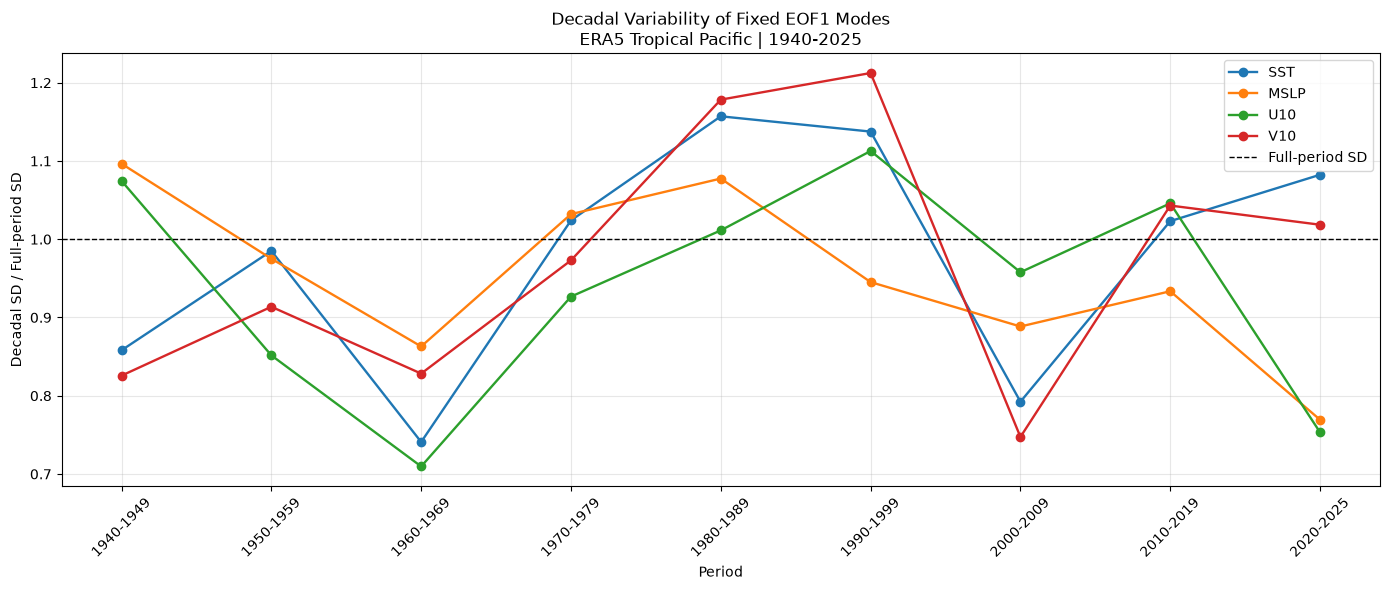

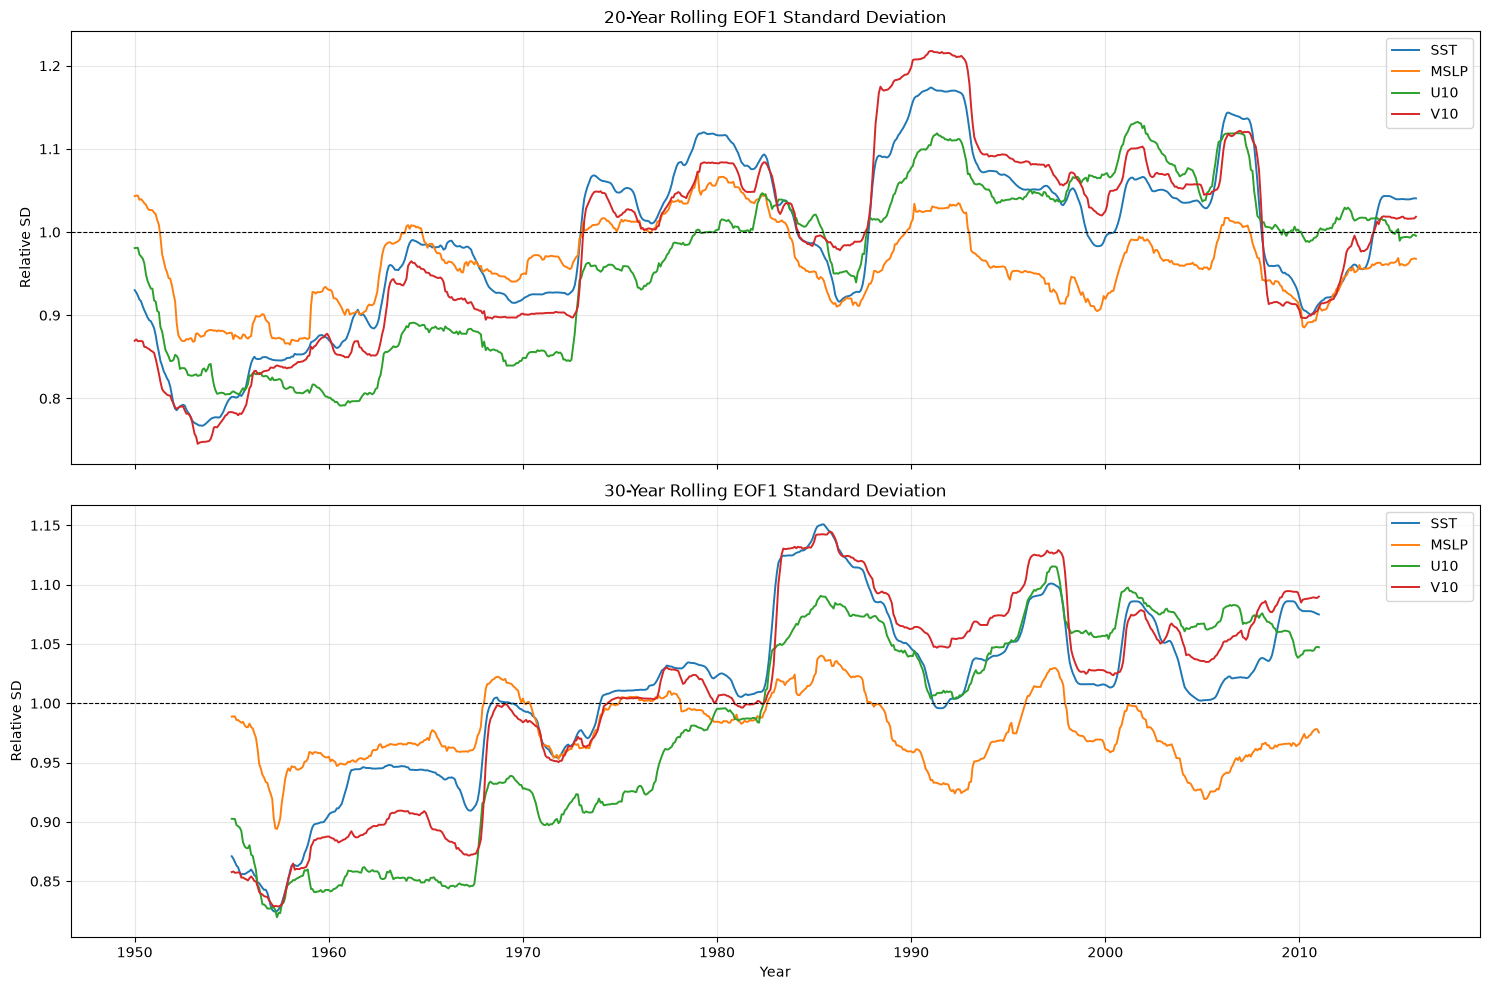

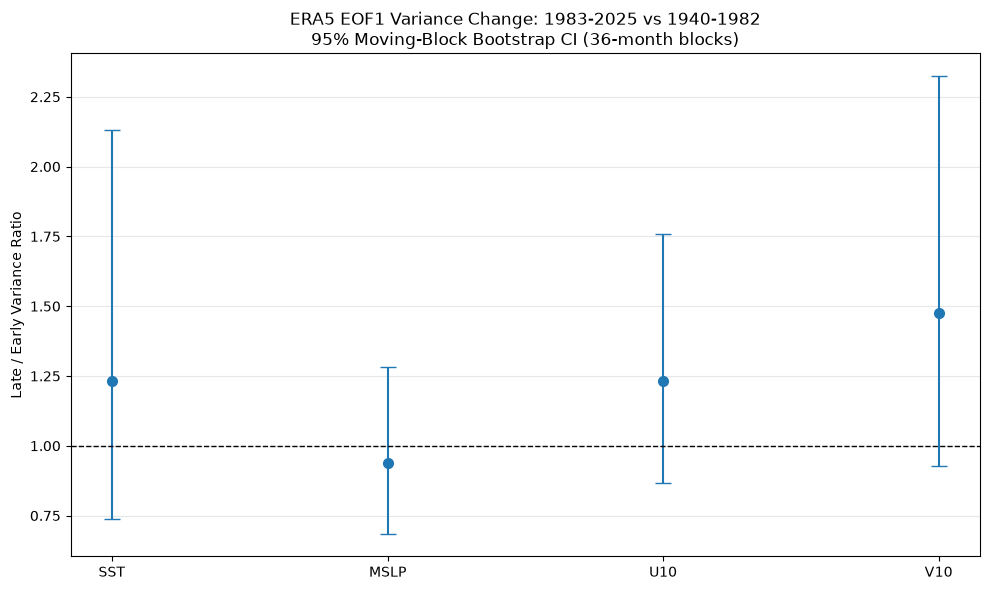


ERA5 ENSO VARIABILITY ANALYSIS COMPLETE

Full-period EOF1 variance explained:
SST: 49.99% | Nino r=0.966
MSLP: 38.17% | Nino r=0.672
U10: 25.47% | Nino r=0.670
V10: 17.49% | Nino r=0.825

Primary early/late results:
          Early SD  Late SD  Variance ratio  CI lower  CI upper  p value
Variable                                                                
SST          0.946    1.051           1.234     0.739     2.133    0.416
MSLP         1.016    0.984           0.937     0.686     1.282    0.682
U10          0.945    1.049           1.233     0.865     1.760    0.223
V10          0.899    1.092           1.475     0.927     2.324    0.148

Outputs:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\variability
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_variability


In [1]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 ENSO-RELATED VARIABILITY ANALYSIS
# SST, MSLP, U10, V10 | 1940-2025
# Fixed full-period tropical Pacific EOF1
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

COARSEN_FACTOR = 8
N_BOOTSTRAP = 3000
BLOCK_LENGTHS = [24, 36, 60]
PRIMARY_BLOCK = 36
RANDOM_SEED = 42

DATA_DIR = Path("data/era5/era5_global")
INDEX_DIR = Path("derived_data/era5/indices")
OUTPUT_DIR = Path("derived_data/era5/variability")
FIG_DIR = Path("figures/era5_variability")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": (
        "era5_sea_surface_temperature_1940_2025.nc",
        "sst"
    ),
    "MSLP": (
        "era5_mean_sea_level_pressure_1940_2025.nc",
        "msl"
    ),
    "U10": (
        "era5_10m_u_component_of_wind_1940_2025.nc",
        "u10"
    ),
    "V10": (
        "era5_10m_v_component_of_wind_1940_2025.nc",
        "v10"
    ),
}

INDEX_FILE = INDEX_DIR / "era5_nino34_1940_2025.nc"

# ============================================================
# 1. LOAD NINO 3.4 INDEX FOR EOF SIGN ALIGNMENT
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds:
    nino = ds["nino34_detrended"].load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(nino.time.values).to_period("M")
)

assert not nino_series.index.has_duplicates

# ============================================================
# 2. LOAD TROPICAL PACIFIC FIELD
# ============================================================

def load_field(filename, variable):

    path = DATA_DIR / filename
    print(f"\nLoading {variable}: {path}")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[variable]

        units = da.attrs.get("units", "")

        # Sort and select before loading data
        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            ),
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        if variable == "sst":
            if units in ("K", "kelvin", "Kelvin"):
                da = da - 273.15
            elif units not in (
                "degC", "C", "celsius", "degrees_C"
            ):
                raise ValueError(f"Unknown SST units: {units}")

        elif variable == "msl":
            if units == "Pa":
                da = da / 100
            elif units not in ("hPa", "mbar"):
                raise ValueError(f"Unknown MSLP units: {units}")

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

    assert da.sizes["time"] == 1032

    print("Loaded shape:", da.shape)
    return da


# ============================================================
# 3. FULL-PERIOD EOF1 AND PROJECTION
# ============================================================

def calculate_fixed_pc(da, name):

    # Remove seasonal cycle
    climatology = da.groupby("time.month").mean("time")
    anomalies = da.groupby("time.month") - climatology

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(nt, ny * nx)

    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(np.float64)

    if X.shape[1] == 0:
        raise ValueError(f"No valid cells for {name}")

    # Full-period detrending
    X = detrend(X, axis=0, type="linear")

    # Square-root area weighting
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(np.cos(np.deg2rad(lat)), 0, None)
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None], (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    positive = weights > 1e-8
    X = X[:, positive]
    weights = weights[positive]

    X_weighted = X * weights

    pca = PCA(n_components=1, svd_solver="full")
    pc = pca.fit_transform(X_weighted)[:, 0]

    # Align time coordinates with Nino 3.4
    months = pd.to_datetime(
        anomalies.time.values
    ).to_period("M")

    pc_series = pd.Series(pc, index=months)

    common = pc_series.index.intersection(
        nino_series.index
    )

    a = pc_series.loc[common].to_numpy()
    b = nino_series.loc[common].to_numpy()

    finite = np.isfinite(a) & np.isfinite(b)

    original_r = np.corrcoef(
        a[finite], b[finite]
    )[0, 1]

    # Approach 3: orient EOF and PC together
    sign = -1 if original_r < 0 else 1

    pc = pc * sign
    eof_weighted = pca.components_[0] * sign

    aligned_r = original_r * sign

    # Full-period standardisation, once only
    pc = (pc - pc.mean()) / pc.std(ddof=1)

    result = pd.Series(
        pc,
        index=months,
        name=name
    )

    print(
        f"{name}: EOF1 variance = "
        f"{pca.explained_variance_ratio_[0]*100:.2f}%"
    )
    print(
        f"  Original r={original_r:+.3f}, "
        f"aligned r={aligned_r:+.3f}, "
        f"flipped={sign == -1}"
    )

    return result, {
        "variance_explained": (
            pca.explained_variance_ratio_[0] * 100
        ),
        "original_r": original_r,
        "aligned_r": aligned_r,
        "flipped": sign == -1,
        "eof_weighted": eof_weighted,
    }


# ============================================================
# 4. CALCULATE ALL FOUR PC TIME SERIES
# ============================================================

pc_series = {}
metadata = {}

for name, (filename, variable) in FILES.items():

    da = load_field(filename, variable)

    series, info = calculate_fixed_pc(da, name)

    pc_series[name] = series
    metadata[name] = info

    del da

pcs = pd.concat(pc_series.values(), axis=1)

assert not pcs.isna().any().any()
assert len(pcs) == 1032

pcs.to_csv(
    OUTPUT_DIR / "fixed_eof1_monthly_pcs.csv"
)

print("\nAll four PC series calculated.")
print(pcs.head())

# ============================================================
# 5. DECADAL STANDARD DEVIATIONS
# ============================================================

decadal_rows = []

for name in FILES:

    for start in range(1940, 2026, 10):

        end = min(start + 9, 2025)

        values = pcs.loc[
            (pcs.index.year >= start) &
            (pcs.index.year <= end),
            name
        ]

        decadal_rows.append({
            "Variable": name,
            "Period": f"{start}-{end}",
            "Months": len(values),
            "Relative SD": values.std(ddof=1),
            "Relative variance": values.var(ddof=1),
        })

decadal_df = pd.DataFrame(decadal_rows)

decadal_df.to_csv(
    OUTPUT_DIR / "decadal_variability.csv",
    index=False
)

# ============================================================
# 6. ROLLING STANDARD DEVIATIONS
# ============================================================

rolling_20 = pcs.rolling(
    window=20 * 12,
    center=True,
    min_periods=20 * 12
).std()

rolling_30 = pcs.rolling(
    window=30 * 12,
    center=True,
    min_periods=30 * 12
).std()

# ============================================================
# 7. MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng):
    """
    Circular moving-block bootstrap.
    Returns a sample of the same length as x.
    """
    x = np.asarray(x, dtype=float)
    n = len(x)

    starts = rng.integers(
        0, n, size=int(np.ceil(n / block))
    )

    indices = np.concatenate([
        (start + np.arange(block)) % n
        for start in starts
    ])[:n]

    return x[indices]


def variance_ratio_test(
    early, late, block, n_bootstrap, seed
):
    """
    1. Bootstrap CI: resample each period separately.
    2. Null test: resample from pooled, separately
       centred early/late data under a common
       stationary-variance approximation.

    The pooled test is exploratory and assumes
    sufficiently similar temporal dependence
    between periods.
    """

    rng = np.random.default_rng(seed)

    early = np.asarray(early, dtype=float)
    late = np.asarray(late, dtype=float)

    early = early[np.isfinite(early)]
    late = late[np.isfinite(late)]

    observed = (
        np.var(late, ddof=1) /
        np.var(early, ddof=1)
    )

    boot_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Pool separately centred periods for null
    pooled = np.concatenate([
        early - early.mean(),
        late - late.mean()
    ])

    for i in range(n_bootstrap):

        # Confidence interval under observed periods
        e = block_sample(early, block, rng)
        l = block_sample(late, block, rng)

        boot_ratios[i] = (
            np.var(l, ddof=1) /
            np.var(e, ddof=1)
        )

        # Null hypothesis: common distribution
        e0 = block_sample(pooled, block, rng)
        l0 = block_sample(pooled, block, rng)

        # Match original sample lengths
        e0 = e0[:len(early)]
        l0 = l0[:len(late)]

        null_ratios[i] = (
            np.var(l0, ddof=1) /
            np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        boot_ratios, [0.025, 0.975]
    )

    # Two-sided test on log variance ratio
    observed_stat = abs(np.log(observed))
    null_stat = abs(np.log(null_ratios))

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return observed, ci_low, ci_high, p_value


# ============================================================
# 8. EARLY VS LATE VARIANCE TESTS
# ============================================================

def run_period_tests(
    data,
    early_start,
    early_end,
    late_start,
    late_end,
    label
):

    rows = []

    for name in FILES:

        early = data.loc[
            (data.index.year >= early_start) &
            (data.index.year <= early_end),
            name
        ].to_numpy()

        late = data.loc[
            (data.index.year >= late_start) &
            (data.index.year <= late_end),
            name
        ].to_numpy()

        for block in BLOCK_LENGTHS:

            ratio, low, high, p = variance_ratio_test(
                early,
                late,
                block,
                N_BOOTSTRAP,
                RANDOM_SEED + block
            )

            rows.append({
                "Analysis": label,
                "Variable": name,
                "Block months": block,
                "Early SD": np.std(early, ddof=1),
                "Late SD": np.std(late, ddof=1),
                "Variance ratio": ratio,
                "CI lower": low,
                "CI upper": high,
                "p value": p,
            })

    return pd.DataFrame(rows)


# Primary equal-length comparison
primary_tests = run_period_tests(
    pcs,
    1940, 1982,
    1983, 2025,
    "1940-2025"
)

# Sensitivity: shorter record, near-equal periods
# Fixed EOFs are still fitted over 1940-2025.
sensitivity_tests = run_period_tests(
    pcs,
    1959, 1991,
    1992, 2025,
    "1959-2025"
)

tests = pd.concat(
    [primary_tests, sensitivity_tests],
    ignore_index=True
)

tests.to_csv(
    OUTPUT_DIR / "variance_bootstrap_tests.csv",
    index=False
)

print("\nPRIMARY VARIANCE TESTS (36-MONTH BLOCKS)")
print(
    primary_tests[
        primary_tests["Block months"] == PRIMARY_BLOCK
    ].round(3).to_string(index=False)
)

# ============================================================
# 9. PLOT DECADAL VARIABILITY
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for name in FILES:

    subset = decadal_df[
        decadal_df["Variable"] == name
    ]

    ax.plot(
        subset["Period"],
        subset["Relative SD"],
        marker="o",
        linewidth=1.7,
        label=name
    )

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Full-period SD"
)

ax.set_title(
    "Decadal Variability of Fixed EOF1 Modes\n"
    "ERA5 Tropical Pacific | 1940-2025"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "decadal_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 10. PLOT ROLLING VARIABILITY
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

dates = pcs.index.to_timestamp()

for name in FILES:

    axes[0].plot(
        dates,
        rolling_20[name],
        label=name,
        linewidth=1.4
    )

    axes[1].plot(
        dates,
        rolling_30[name],
        label=name,
        linewidth=1.4
    )

for ax, years in zip(axes, [20, 30]):

    ax.axhline(
        1, color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(
        f"{years}-Year Rolling EOF1 Standard Deviation"
    )

    ax.set_ylabel("Relative SD")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "rolling_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 11. PLOT VARIANCE RATIOS WITH 95% CI
# ============================================================

selected = primary_tests[
    primary_tests["Block months"] == PRIMARY_BLOCK
].set_index("Variable").loc[list(FILES)]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(selected))

ratios = selected["Variance ratio"].to_numpy()
lower = selected["CI lower"].to_numpy()
upper = selected["CI upper"].to_numpy()

ax.errorbar(
    x,
    ratios,
    yerr=[
        ratios - lower,
        upper - ratios
    ],
    fmt="o",
    capsize=6,
    markersize=7
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(selected.index)

ax.set_ylabel("Late / Early Variance Ratio")

ax.set_title(
    "ERA5 EOF1 Variance Change: 1983-2025 vs 1940-1982\n"
    "95% Moving-Block Bootstrap CI (36-month blocks)"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "variance_ratio_confidence_intervals.png",
    dpi=200
)
plt.show()

# ============================================================
# 12. SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ERA5 ENSO VARIABILITY ANALYSIS COMPLETE")
print("=" * 65)

print("\nFull-period EOF1 variance explained:")

for name, info in metadata.items():
    print(
        f"{name}: "
        f"{info['variance_explained']:.2f}% "
        f"| Nino r={info['aligned_r']:.3f}"
    )

print("\nPrimary early/late results:")

print(
    selected[
        ["Early SD", "Late SD",
         "Variance ratio", "CI lower",
         "CI upper", "p value"]
    ].round(3)
)

print("\nOutputs:")
print(OUTPUT_DIR.resolve())
print(FIG_DIR.resolve())

print("=" * 65)


ERA5 NINO 3.4 VARIABILITY ANALYSIS
Months: 1032
First month: 1940-01
Last month: 2025-12

Early period SD: 0.8354
Late period SD: 0.9153
Variance ratio: 1.2005

Testing 24-month blocks...

Testing 36-month blocks...

Testing 60-month blocks...

BOOTSTRAP RESULTS
 Block months  Early SD  Late SD  Variance ratio  CI lower  CI upper  p value
           24    0.8354   0.9153          1.2005    0.7627    1.9418   0.4431
           36    0.8354   0.9153          1.2005    0.7591    1.9641   0.4499
           60    0.8354   0.9153          1.2005    0.7738    1.9386   0.4371


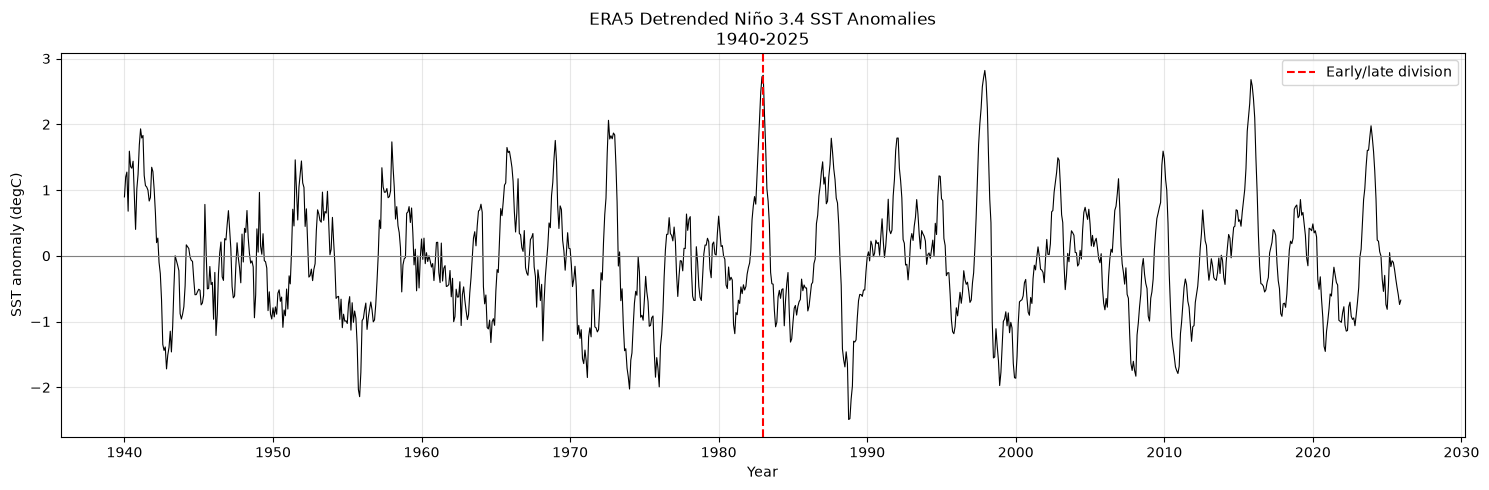

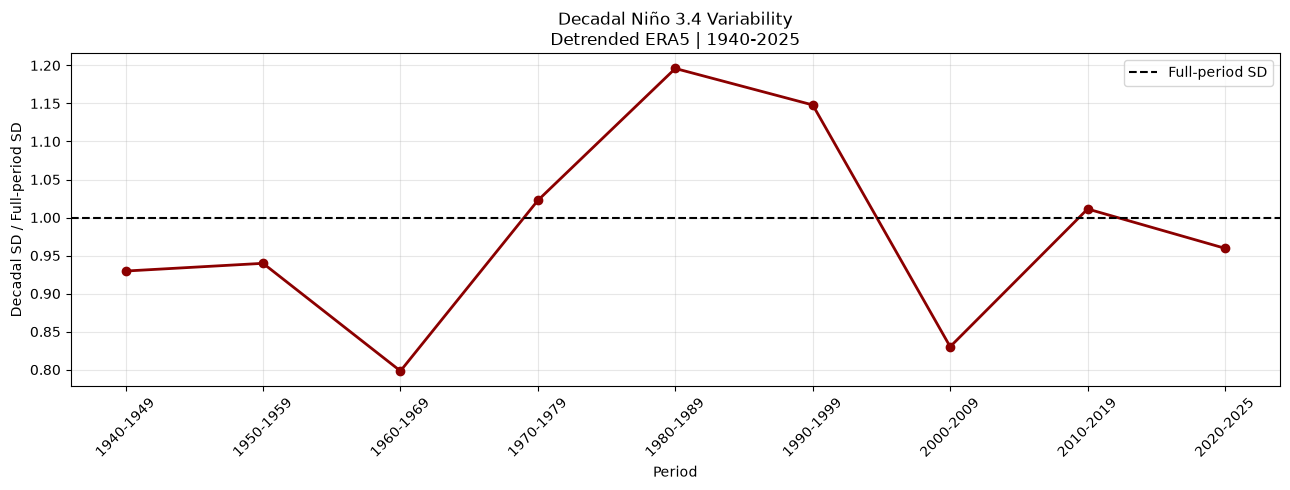

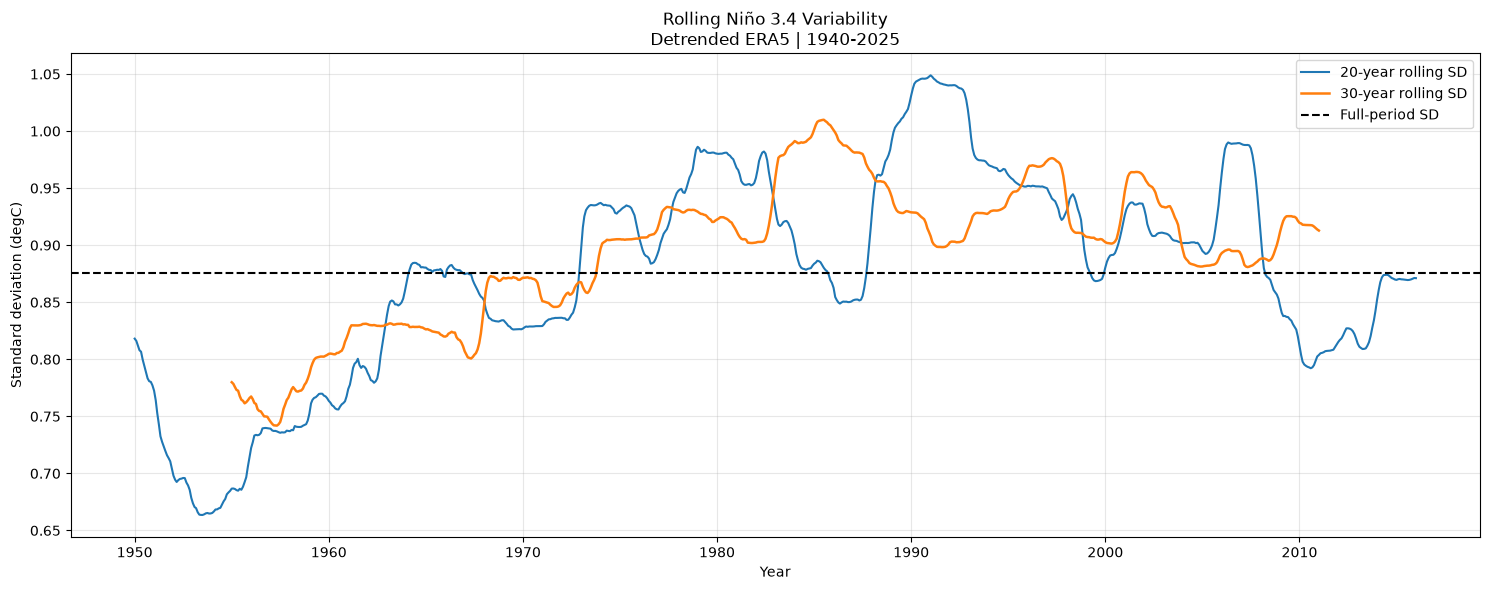

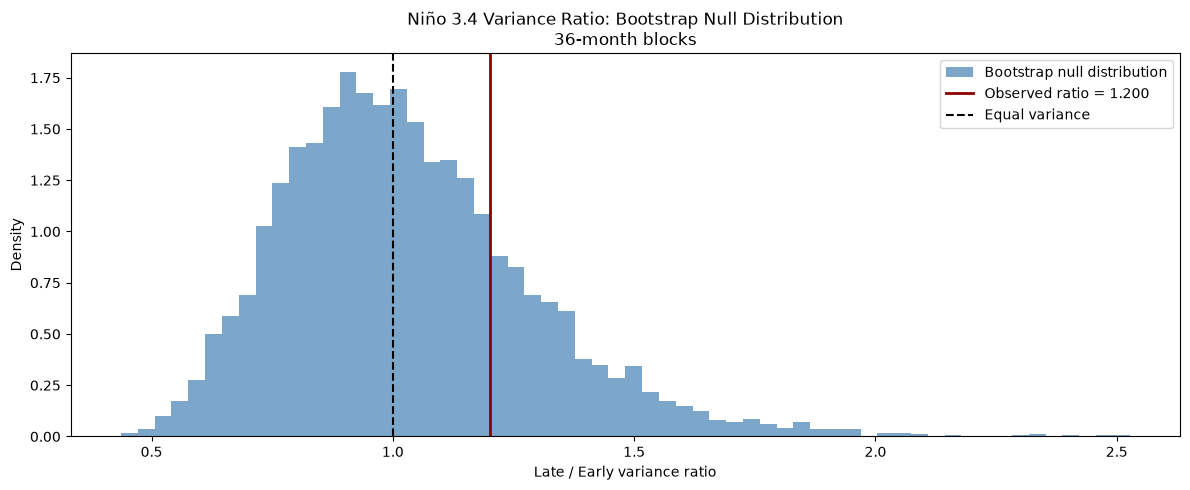


ERA5 NINO 3.4 VARIABILITY TEST SUMMARY
Early SD: 0.8354 degC
Late SD: 0.9153 degC
Variance ratio: 1.2005
95% CI: [0.7591, 1.9641]
Bootstrap p-value: 0.4499

No statistically significant variance difference detected at the 5% level.

Outputs:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\nino34_variability
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_nino34_variability


In [2]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# ERA5 NINO 3.4 VARIABILITY ANALYSIS
# 1940-2025 | Detrended monthly SST anomalies
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_START = 1940
EARLY_END = 1982

LATE_START = 1983
LATE_END = 2025

BLOCK_LENGTHS = [24, 36, 60]
PRIMARY_BLOCK = 36

N_BOOTSTRAP = 5000
RANDOM_SEED = 42

INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

OUTPUT_DIR = Path(
    "derived_data/era5/nino34_variability"
)

FIG_DIR = Path(
    "figures/era5_nino34_variability"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. LOAD NINO 3.4 INDEX
# ============================================================

print("=" * 65)
print("ERA5 NINO 3.4 VARIABILITY ANALYSIS")
print("=" * 65)

with xr.open_dataset(INDEX_FILE) as ds:

    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

dates = pd.to_datetime(nino.time.values)

series = pd.Series(
    nino.values,
    index=dates.to_period("M"),
    name="Nino34"
).sort_index()

expected = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert series.index.equals(expected), (
    "Unexpected or missing monthly observations"
)

assert np.isfinite(series.values).all(), (
    "Niño 3.4 index contains missing values"
)

print("Months:", len(series))
print("First month:", series.index[0])
print("Last month:", series.index[-1])

# ============================================================
# 2. EARLY AND LATE PERIODS
# ============================================================

early = series.loc[
    f"{EARLY_START}-01":f"{EARLY_END}-12"
].to_numpy()

late = series.loc[
    f"{LATE_START}-01":f"{LATE_END}-12"
].to_numpy()

early_std = np.std(early, ddof=1)
late_std = np.std(late, ddof=1)

observed_ratio = (
    np.var(late, ddof=1) /
    np.var(early, ddof=1)
)

print("\nEarly period SD:", round(early_std, 4))
print("Late period SD:", round(late_std, 4))
print("Variance ratio:", round(observed_ratio, 4))

# ============================================================
# 3. CIRCULAR MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng, size=None):

    x = np.asarray(x, dtype=float)

    n = len(x)

    if size is None:
        size = n

    n_blocks = int(np.ceil(size / block))

    starts = rng.integers(
        0, n, size=n_blocks
    )

    indices = (
        starts[:, None] +
        np.arange(block)[None, :]
    ) % n

    return x[indices.ravel()[:size]]


def variance_ratio_test(
    early,
    late,
    block,
    n_bootstrap=5000,
    seed=42
):

    rng = np.random.default_rng(seed)

    n_early = len(early)
    n_late = len(late)

    observed = (
        np.var(late, ddof=1) /
        np.var(early, ddof=1)
    )

    bootstrap_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Pool centred observations for approximate null
    pooled = np.concatenate([
        early - np.mean(early),
        late - np.mean(late)
    ])

    for i in range(n_bootstrap):

        # Bootstrap confidence interval:
        # resample each period independently
        e = block_sample(
            early, block, rng, n_early
        )

        l = block_sample(
            late, block, rng, n_late
        )

        bootstrap_ratios[i] = (
            np.var(l, ddof=1) /
            np.var(e, ddof=1)
        )

        # Null distribution:
        # both samples from pooled process
        e0 = block_sample(
            pooled, block, rng, n_early
        )

        l0 = block_sample(
            pooled, block, rng, n_late
        )

        null_ratios[i] = (
            np.var(l0, ddof=1) /
            np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        bootstrap_ratios,
        [0.025, 0.975]
    )

    # Two-sided log variance-ratio test
    observed_stat = abs(np.log(observed))

    null_stat = np.abs(
        np.log(null_ratios)
    )

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return {
        "observed": observed,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
        "bootstrap_ratios": bootstrap_ratios,
        "null_ratios": null_ratios,
    }

# ============================================================
# 4. RUN BOOTSTRAP SENSITIVITY TESTS
# ============================================================

results = {}
rows = []

for block in BLOCK_LENGTHS:

    print(f"\nTesting {block}-month blocks...")

    result = variance_ratio_test(
        early,
        late,
        block,
        N_BOOTSTRAP,
        RANDOM_SEED + block
    )

    results[block] = result

    rows.append({
        "Block months": block,
        "Early SD": early_std,
        "Late SD": late_std,
        "Variance ratio": result["observed"],
        "CI lower": result["ci_low"],
        "CI upper": result["ci_high"],
        "p value": result["p_value"],
    })

summary = pd.DataFrame(rows)

print("\n" + "=" * 65)
print("BOOTSTRAP RESULTS")
print("=" * 65)

print(
    summary.round(4).to_string(index=False)
)

summary.to_csv(
    OUTPUT_DIR / "nino34_bootstrap_results.csv",
    index=False
)

# ============================================================
# 5. DECADAL VARIABILITY
# ============================================================

full_std = series.std(ddof=1)

decadal_rows = []

for start in range(START_YEAR, END_YEAR + 1, 10):

    end = min(start + 9, END_YEAR)

    subset = series.loc[
        f"{start}-01":f"{end}-12"
    ]

    decadal_rows.append({
        "Period": f"{start}-{end}",
        "Months": len(subset),
        "SD (degC)": subset.std(ddof=1),
        "Variance (degC2)": subset.var(ddof=1),
        "Relative SD": (
            subset.std(ddof=1) / full_std
        ),
    })

decadal_df = pd.DataFrame(decadal_rows)

decadal_df.to_csv(
    OUTPUT_DIR / "nino34_decadal_variability.csv",
    index=False
)

# ============================================================
# 6. ROLLING STANDARD DEVIATIONS
# ============================================================

rolling_20 = series.rolling(
    20 * 12,
    center=True,
    min_periods=20 * 12
).std()

rolling_30 = series.rolling(
    30 * 12,
    center=True,
    min_periods=30 * 12
).std()

# ============================================================
# 7. PLOT MONTHLY NINO 3.4 INDEX
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    series.index.to_timestamp(),
    series.values,
    color="black",
    linewidth=0.8
)

ax.axhline(
    0, color="grey", linewidth=0.8
)

ax.axvline(
    pd.Timestamp("1983-01-01"),
    color="red",
    linestyle="--",
    label="Early/late division"
)

ax.set_title(
    "ERA5 Detrended Niño 3.4 SST Anomalies\n"
    "1940-2025"
)

ax.set_xlabel("Year")
ax.set_ylabel("SST anomaly (degC)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_detrended_timeseries.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. PLOT DECADAL STANDARD DEVIATION
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    decadal_df["Period"],
    decadal_df["Relative SD"],
    marker="o",
    linewidth=2,
    color="darkred"
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Full-period SD"
)

ax.set_title(
    "Decadal Niño 3.4 Variability\n"
    "Detrended ERA5 | 1940-2025"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_decadal_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 9. PLOT ROLLING STANDARD DEVIATIONS
# ============================================================

fig, ax = plt.subplots(figsize=(15, 6))

dates = series.index.to_timestamp()

ax.plot(
    dates,
    rolling_20,
    label="20-year rolling SD",
    linewidth=1.5
)

ax.plot(
    dates,
    rolling_30,
    label="30-year rolling SD",
    linewidth=1.8
)

ax.axhline(
    full_std,
    color="black",
    linestyle="--",
    label="Full-period SD"
)

ax.set_title(
    "Rolling Niño 3.4 Variability\n"
    "Detrended ERA5 | 1940-2025"
)

ax.set_ylabel("Standard deviation (degC)")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_rolling_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 10. PLOT BOOTSTRAP NULL DISTRIBUTION
# ============================================================

primary = results[PRIMARY_BLOCK]

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(
    primary["null_ratios"],
    bins=60,
    density=True,
    color="steelblue",
    alpha=0.7,
    label="Bootstrap null distribution"
)

ax.axvline(
    observed_ratio,
    color="darkred",
    linewidth=2,
    label=f"Observed ratio = {observed_ratio:.3f}"
)

ax.axvline(
    1,
    color="black",
    linestyle="--",
    label="Equal variance"
)

ax.set_title(
    "Niño 3.4 Variance Ratio: Bootstrap Null Distribution\n"
    "36-month blocks"
)

ax.set_xlabel("Late / Early variance ratio")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_bootstrap_null_distribution.png",
    dpi=200
)
plt.show()

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

primary_row = summary[
    summary["Block months"] == PRIMARY_BLOCK
].iloc[0]

print("\n" + "=" * 65)
print("ERA5 NINO 3.4 VARIABILITY TEST SUMMARY")
print("=" * 65)

print(f"Early SD: {early_std:.4f} degC")
print(f"Late SD: {late_std:.4f} degC")

print(
    f"Variance ratio: "
    f"{observed_ratio:.4f}"
)

print(
    f"95% CI: "
    f"[{primary_row['CI lower']:.4f}, "
    f"{primary_row['CI upper']:.4f}]"
)

print(
    f"Bootstrap p-value: "
    f"{primary_row['p value']:.4f}"
)

if primary_row["p value"] < 0.05:
    print(
        "\nStatistically significant variance "
        "difference at the 5% level "
        "under the bootstrap null model."
    )
else:
    print(
        "\nNo statistically significant variance "
        "difference detected at the 5% level."
    )

print("\nOutputs:")
print(OUTPUT_DIR.resolve())
print(FIG_DIR.resolve())

print("=" * 65)


ERA5 ENSO VARIABILITY COMPARISON

Data shape: (1032, 3)

Full-period standard deviations:
Nino34               1.0
SST_EOF1             1.0
Atmospheric_MEOF1    1.0
dtype: float64

BOOTSTRAP RESULTS
            Index  Block months  Early SD  Late SD  Variance ratio  CI lower  CI upper  p value
           Nino34            24    0.9536   1.0449          1.2005    0.7627    1.9418   0.4431
           Nino34            36    0.9536   1.0449          1.2005    0.7591    1.9641   0.4499
           Nino34            60    0.9536   1.0449          1.2005    0.7738    1.9386   0.4371
           Nino34            84    0.9536   1.0449          1.2005    0.8075    1.8596   0.3923
           Nino34           120    0.9536   1.0449          1.2005    0.8803    1.7126   0.3359
         SST_EOF1            24    0.9460   1.0506          1.2335    0.7625    2.0520   0.4061
         SST_EOF1            36    0.9460   1.0506          1.2335    0.7513    2.0769   0.4237
         SST_EOF1            60  

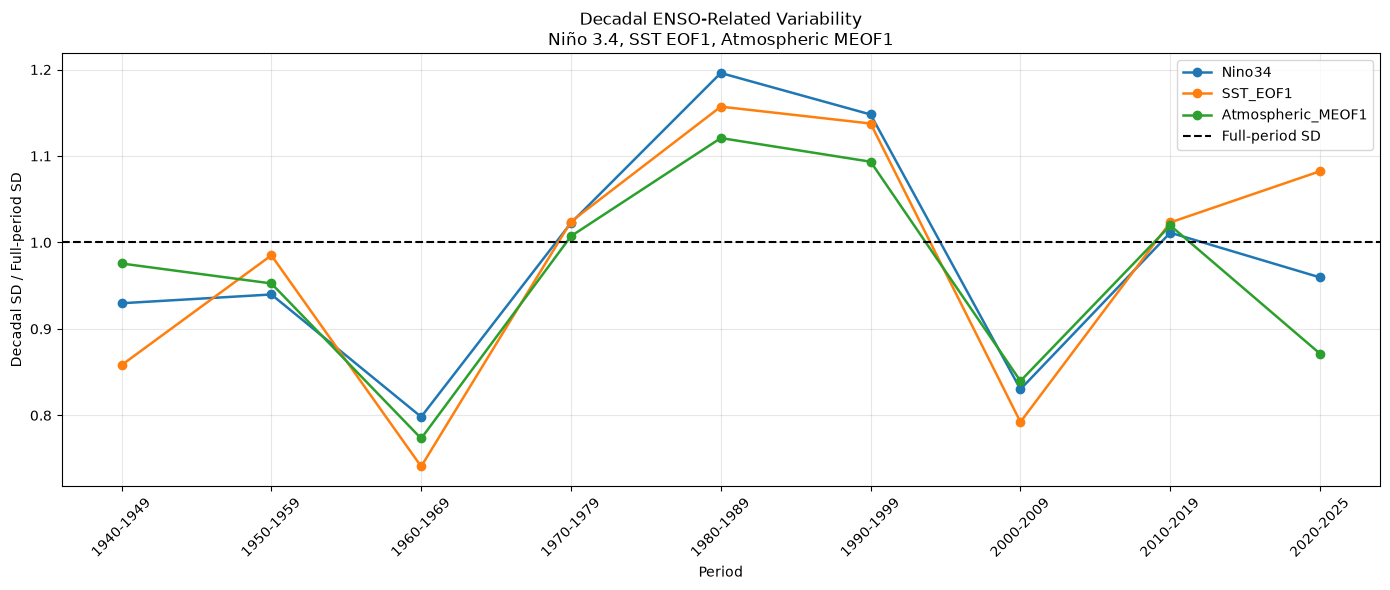

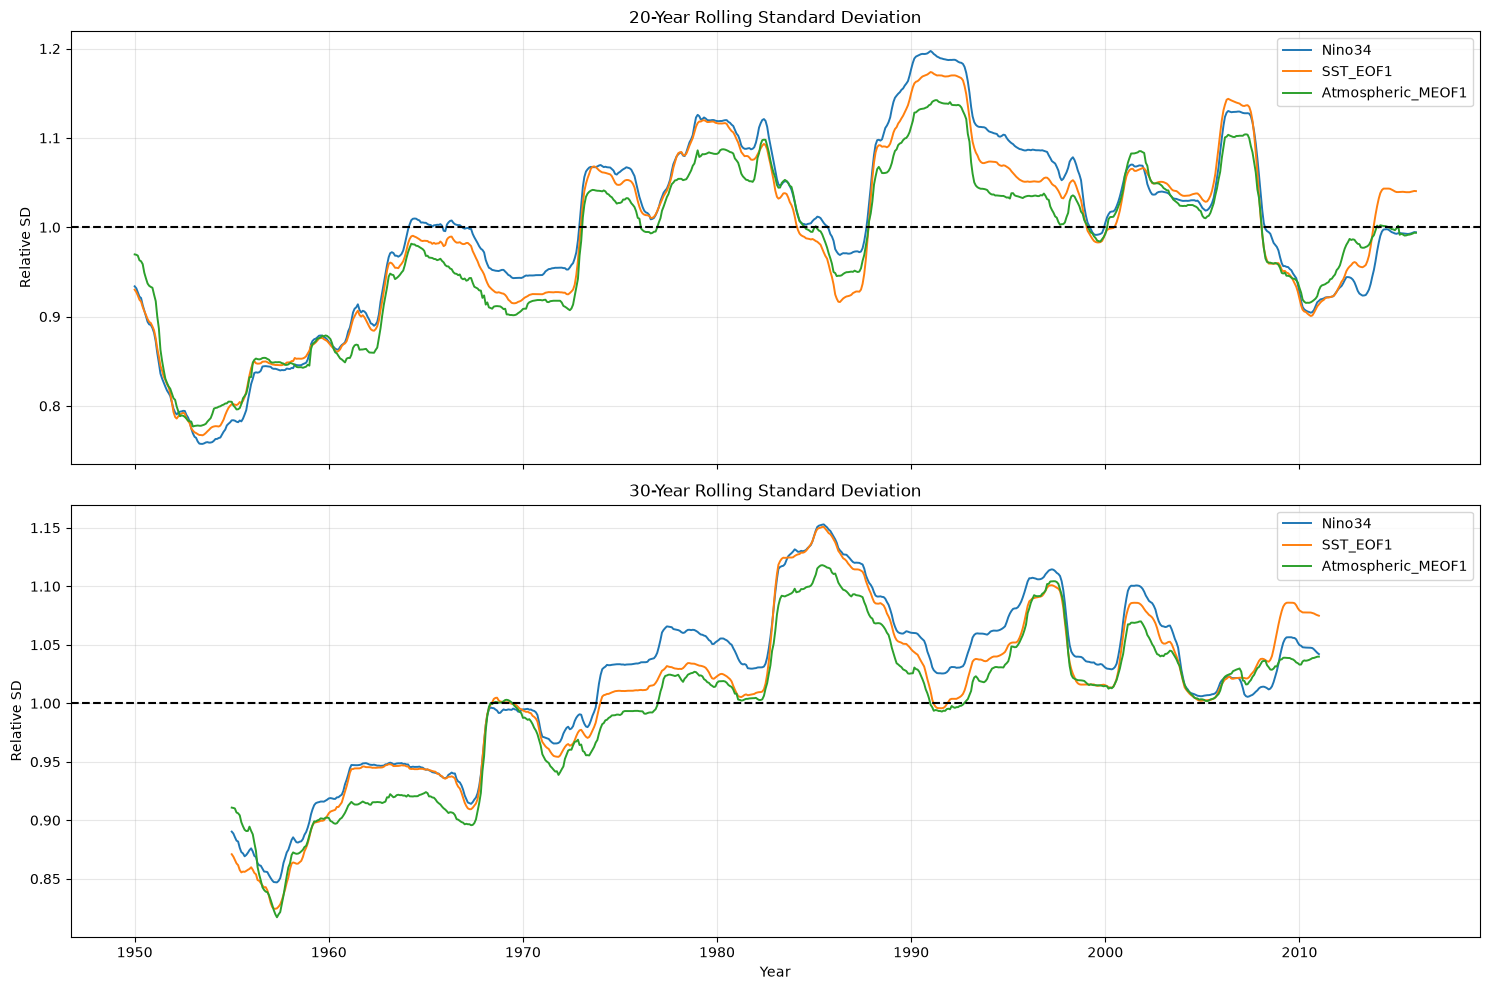

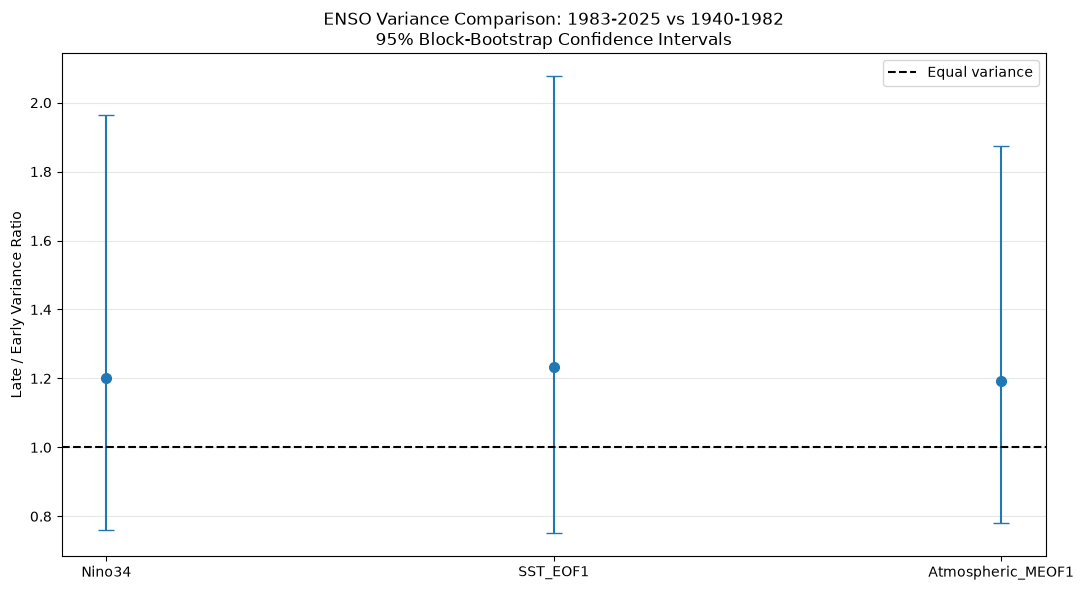


ENSO VARIABILITY COMPARISON COMPLETE

Primary results:
                   Block months  Early SD  Late SD  Variance ratio  CI lower  \
Index                                                                          
Nino34                       36    0.9536   1.0449          1.2005    0.7591   
SST_EOF1                     36    0.9460   1.0506          1.2335    0.7513   
Atmospheric_MEOF1            36    0.9542   1.0425          1.1936    0.7819   

                   CI upper  p value  
Index                                 
Nino34               1.9641   0.4499  
SST_EOF1             2.0769   0.4237  
Atmospheric_MEOF1    1.8756   0.4243  

Files saved to:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\enso_variability_comparison
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_enso_variability_comparison


In [3]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# ERA5 ENSO VARIABILITY COMPARISON
#
# 1. Nino 3.4 SST index
# 2. Tropical Pacific SST EOF1
# 3. Atmospheric MEOF1 (without SST)
#
# 1940-2025 | Moving-block bootstrap
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_START, EARLY_END = 1940, 1982
LATE_START, LATE_END = 1983, 2025

BLOCK_LENGTHS = [24, 36, 60, 84, 120]
PRIMARY_BLOCK = 36

N_BOOTSTRAP = 5000
RANDOM_SEED = 42

INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

SST_PC_FILE = Path(
    "derived_data/era5/fixed_eof/"
    "sst_fixed_eof1_pc.csv"
)

ATM_PC_FILE = Path(
    "derived_data/era5/multivariate_eof_no_sst/"
    "atmospheric_monthly_pcs.csv"
)

OUTPUT_DIR = Path(
    "derived_data/era5/enso_variability_comparison"
)

FIG_DIR = Path(
    "figures/era5_enso_variability_comparison"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. LOAD NINO 3.4
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds:
    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M"),
    name="Nino34"
)

# ============================================================
# 2. LOAD SST EOF1 PC
# ============================================================

sst_df = pd.read_csv(
    SST_PC_FILE,
    parse_dates=["time"]
)

sst_series = pd.Series(
    sst_df["pc"].values,
    index=pd.to_datetime(
        sst_df["time"]
    ).dt.to_period("M"),
    name="SST_EOF1"
)

# ============================================================
# 3. LOAD ATMOSPHERIC MEOF1 PC
# ============================================================

atm_df = pd.read_csv(
    ATM_PC_FILE,
    index_col=0
)

atm_series = pd.Series(
    atm_df["PC1"].values,
    index=pd.PeriodIndex(
        atm_df.index,
        freq="M"
    ),
    name="Atmospheric_MEOF1"
)

# ============================================================
# 4. ALIGN AND STANDARDISE
# ============================================================

data = pd.concat(
    [nino_series, sst_series, atm_series],
    axis=1
).sort_index()

expected = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert data.index.equals(expected), (
    "Missing or unexpected monthly observations"
)

assert np.isfinite(data.values).all(), (
    "Missing or non-finite values detected"
)

# Standardise each complete series once.
# Variance ratios are unaffected by this scaling.
data = (
    data - data.mean()
) / data.std(ddof=1)

print("=" * 65)
print("ERA5 ENSO VARIABILITY COMPARISON")
print("=" * 65)

print("\nData shape:", data.shape)
print("\nFull-period standard deviations:")
print(data.std(ddof=1).round(4))

data.to_csv(
    OUTPUT_DIR / "aligned_standardised_indices.csv"
)

# ============================================================
# 5. CIRCULAR MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng, size=None):

    x = np.asarray(x, dtype=float)

    n = len(x)

    if size is None:
        size = n

    starts = rng.integers(
        0,
        n,
        size=int(np.ceil(size / block))
    )

    indices = (
        starts[:, None]
        + np.arange(block)[None, :]
    ) % n

    return x[indices.ravel()[:size]]


def variance_ratio_test(
    early,
    late,
    block,
    n_bootstrap,
    rng
):

    early = np.asarray(early, dtype=float)
    late = np.asarray(late, dtype=float)

    n_early = len(early)
    n_late = len(late)

    observed = (
        np.var(late, ddof=1)
        / np.var(early, ddof=1)
    )

    bootstrap_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Approximate null: pooled, centred process
    pooled = np.concatenate([
        early - early.mean(),
        late - late.mean()
    ])

    for i in range(n_bootstrap):

        # Bootstrap CI:
        # sample early and late separately
        e = block_sample(
            early, block, rng, n_early
        )

        l = block_sample(
            late, block, rng, n_late
        )

        bootstrap_ratios[i] = (
            np.var(l, ddof=1)
            / np.var(e, ddof=1)
        )

        # Bootstrap null:
        # both periods from pooled process
        e0 = block_sample(
            pooled, block, rng, n_early
        )

        l0 = block_sample(
            pooled, block, rng, n_late
        )

        null_ratios[i] = (
            np.var(l0, ddof=1)
            / np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        bootstrap_ratios,
        [0.025, 0.975]
    )

    observed_stat = abs(np.log(observed))
    null_stat = np.abs(np.log(null_ratios))

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return observed, ci_low, ci_high, p_value


# ============================================================
# 6. RUN BOOTSTRAP TESTS
# ============================================================

rows = []

for name in data.columns:

    early = data.loc[
        f"{EARLY_START}-01":
        f"{EARLY_END}-12",
        name
    ].to_numpy()

    late = data.loc[
        f"{LATE_START}-01":
        f"{LATE_END}-12",
        name
    ].to_numpy()

    for block in BLOCK_LENGTHS:

        rng = np.random.default_rng(
            RANDOM_SEED + block
        )

        ratio, low, high, p = variance_ratio_test(
            early,
            late,
            block,
            N_BOOTSTRAP,
            rng
        )

        rows.append({
            "Index": name,
            "Block months": block,
            "Early SD": np.std(early, ddof=1),
            "Late SD": np.std(late, ddof=1),
            "Variance ratio": ratio,
            "CI lower": low,
            "CI upper": high,
            "p value": p,
        })

results = pd.DataFrame(rows)

results.to_csv(
    OUTPUT_DIR / "bootstrap_variance_results.csv",
    index=False
)

print("\nBOOTSTRAP RESULTS")
print(
    results.round(4).to_string(index=False)
)

# ============================================================
# 7. PRIMARY RESULTS
# ============================================================

primary = results[
    results["Block months"] == PRIMARY_BLOCK
].set_index("Index")

print("\n" + "=" * 65)
print("PRIMARY RESULTS: 36-MONTH BLOCKS")
print("=" * 65)

print(
    primary[
        ["Early SD", "Late SD",
         "Variance ratio", "CI lower",
         "CI upper", "p value"]
    ].round(4)
)

# ============================================================
# 8. DECADAL VARIABILITY
# ============================================================

decadal_rows = []

for name in data.columns:

    for start in range(
        START_YEAR, END_YEAR + 1, 10
    ):

        end = min(start + 9, END_YEAR)

        subset = data.loc[
            f"{start}-01":f"{end}-12",
            name
        ]

        decadal_rows.append({
            "Index": name,
            "Period": f"{start}-{end}",
            "Months": len(subset),
            "Relative SD": subset.std(ddof=1),
            "Relative variance": subset.var(ddof=1),
        })

decadal = pd.DataFrame(decadal_rows)

decadal.to_csv(
    OUTPUT_DIR / "decadal_variability.csv",
    index=False
)

# ============================================================
# 9. PLOT DECADAL VARIABILITY
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for name in data.columns:

    subset = decadal[
        decadal["Index"] == name
    ]

    ax.plot(
        subset["Period"],
        subset["Relative SD"],
        marker="o",
        linewidth=1.8,
        label=name
    )

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Full-period SD"
)

ax.set_title(
    "Decadal ENSO-Related Variability\n"
    "Niño 3.4, SST EOF1, Atmospheric MEOF1"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "decadal_variability_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 10. ROLLING STANDARD DEVIATIONS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

dates = data.index.to_timestamp()

for name in data.columns:

    for ax, window in zip(
        axes, [20, 30]
    ):

        rolling = data[name].rolling(
            window * 12,
            center=True,
            min_periods=window * 12
        ).std()

        ax.plot(
            dates,
            rolling,
            label=name,
            linewidth=1.4
        )

for ax, window in zip(
    axes, [20, 30]
):

    ax.axhline(
        1,
        color="black",
        linestyle="--"
    )

    ax.set_title(
        f"{window}-Year Rolling Standard Deviation"
    )

    ax.set_ylabel("Relative SD")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "rolling_variability_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 11. VARIANCE RATIO COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

names = list(primary.index)
x = np.arange(len(names))

ratios = primary["Variance ratio"].values
lower = primary["CI lower"].values
upper = primary["CI upper"].values

ax.errorbar(
    x,
    ratios,
    yerr=[
        ratios - lower,
        upper - ratios
    ],
    fmt="o",
    capsize=6,
    markersize=7
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Equal variance"
)

ax.set_xticks(x)
ax.set_xticklabels(names)

ax.set_ylabel("Late / Early Variance Ratio")

ax.set_title(
    "ENSO Variance Comparison: 1983-2025 vs 1940-1982\n"
    "95% Block-Bootstrap Confidence Intervals"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "variance_ratio_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 12. SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ENSO VARIABILITY COMPARISON COMPLETE")
print("=" * 65)

print("\nPrimary results:")
print(primary.round(4))

print("\nFiles saved to:")
print(OUTPUT_DIR.resolve())
print(FIG_DIR.resolve())

print("=" * 65)


ERA5 TROPICAL PACIFIC EOF1 VARIABILITY ANALYSIS
Niño 3.4 months: 1032

Loading SST: data\era5\era5_global\era5_sea_surface_temperature_1940_2025.nc
Tropical Pacific shape: (1032, 20, 80)
Units: degC

Calculating SST EOF1...
SST: EOF1 explained variance = 49.99%
  Original Niño r=+0.966, aligned r=+0.966, flipped=False

Loading MSLP: data\era5\era5_global\era5_mean_sea_level_pressure_1940_2025.nc
Tropical Pacific shape: (1032, 20, 80)
Units: hPa

Calculating MSLP EOF1...
MSLP: EOF1 explained variance = 38.17%
  Original Niño r=-0.672, aligned r=+0.672, flipped=True

Loading U10: data\era5\era5_global\era5_10m_u_component_of_wind_1940_2025.nc
Tropical Pacific shape: (1032, 20, 80)
Units: m/s

Calculating U10 EOF1...
U10: EOF1 explained variance = 25.47%
  Original Niño r=+0.670, aligned r=+0.670, flipped=False

Loading V10: data\era5\era5_global\era5_10m_v_component_of_wind_1940_2025.nc
Tropical Pacific shape: (1032, 20, 80)
Units: m/s

Calculating V10 EOF1...
V10: EOF1 explained varianc

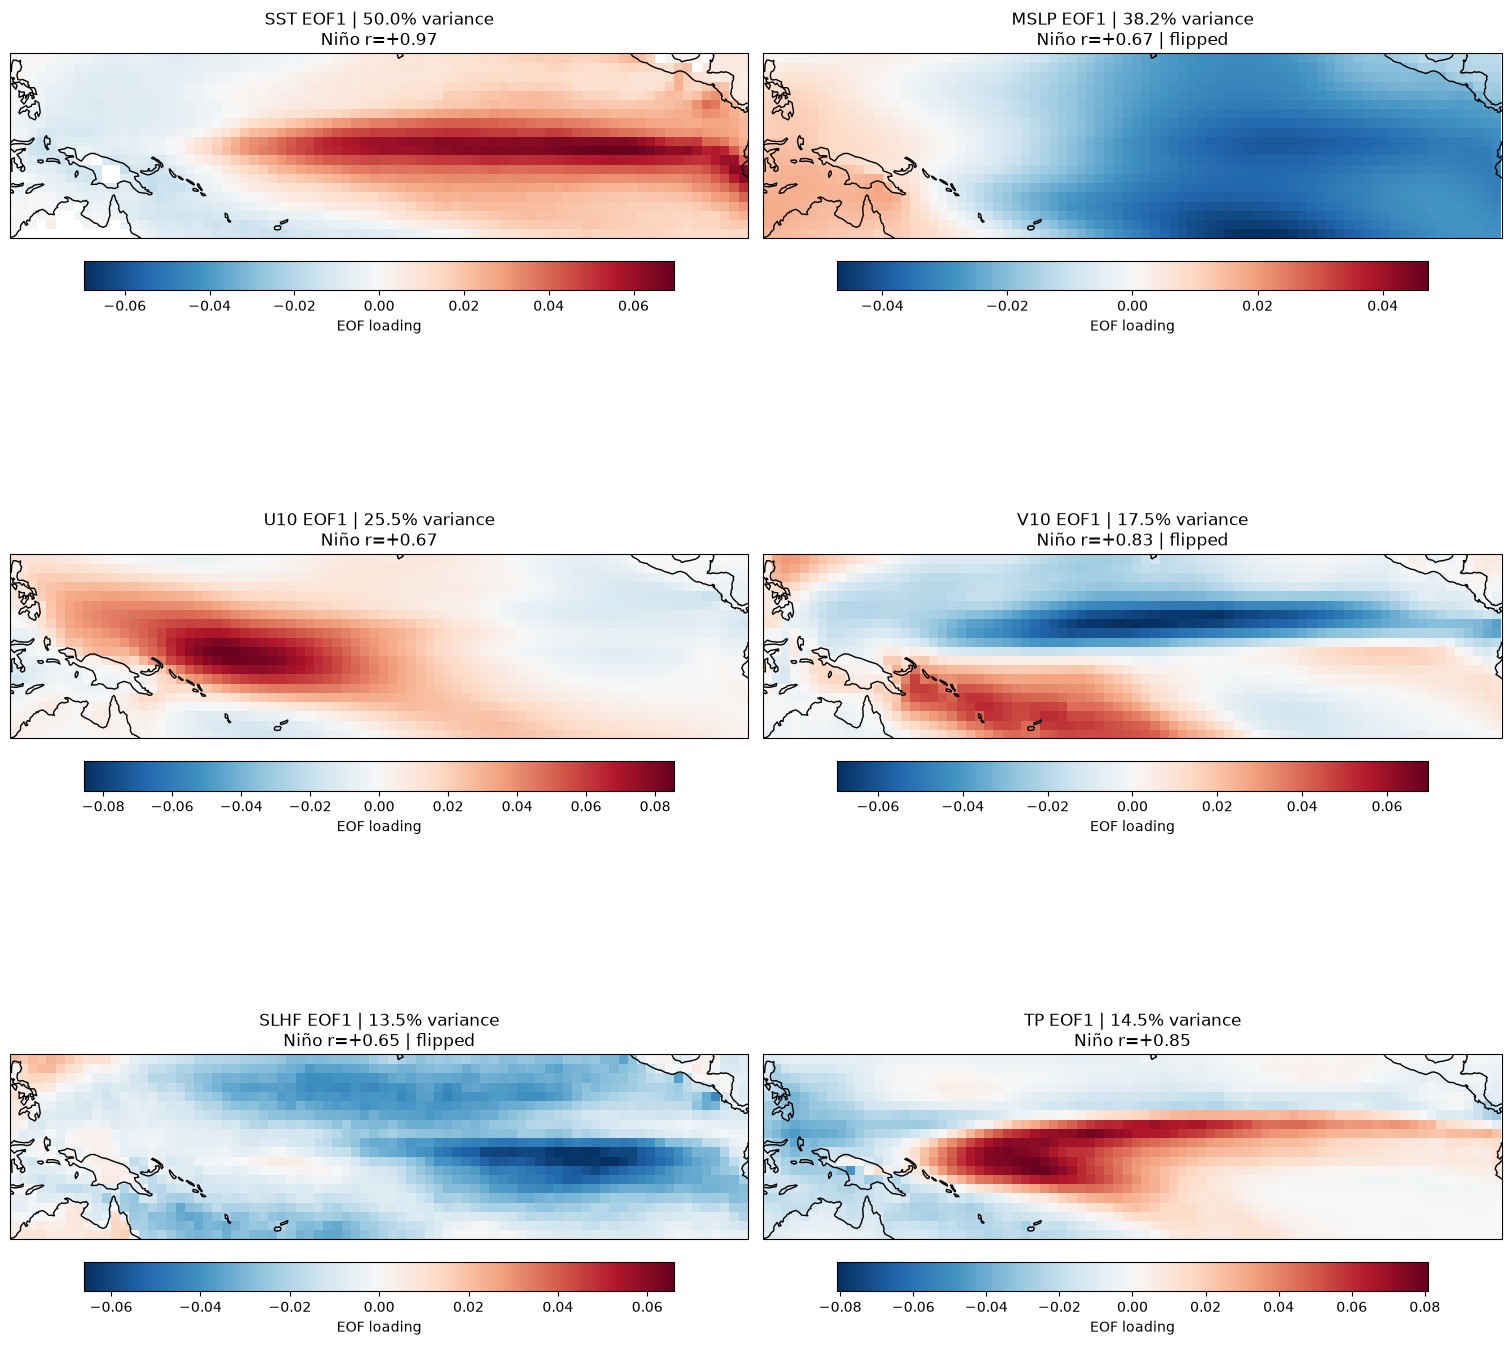

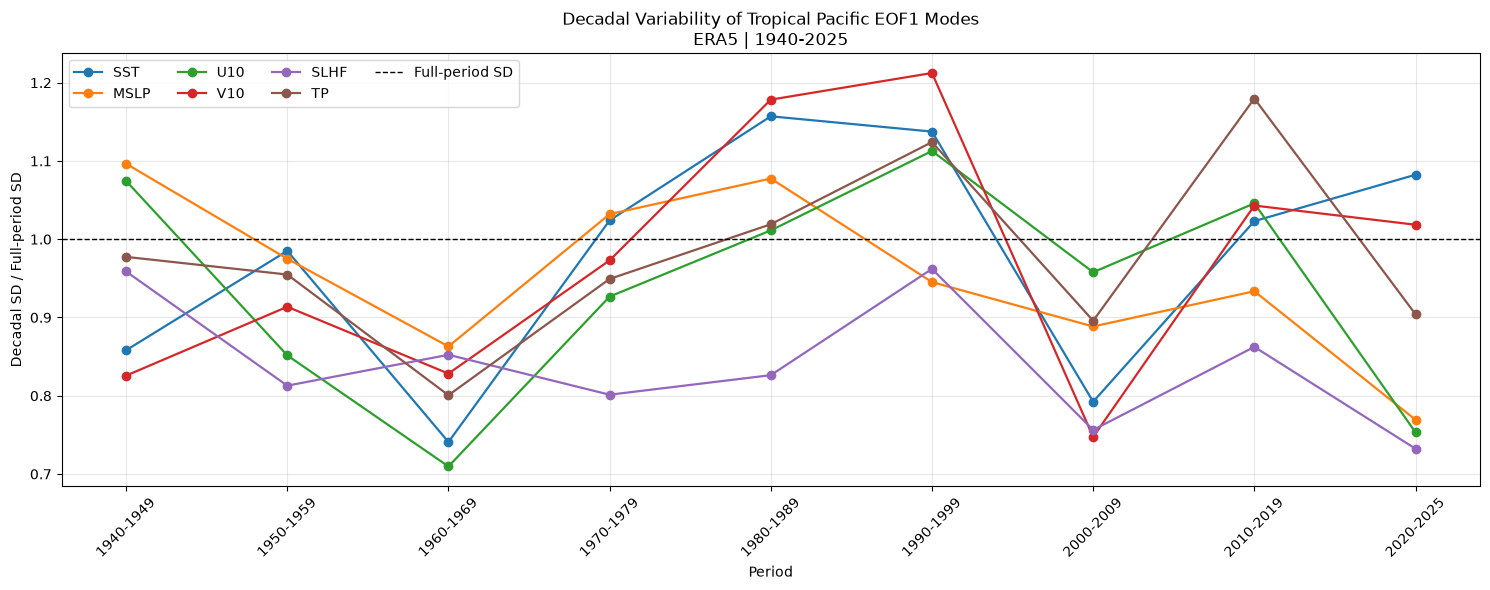

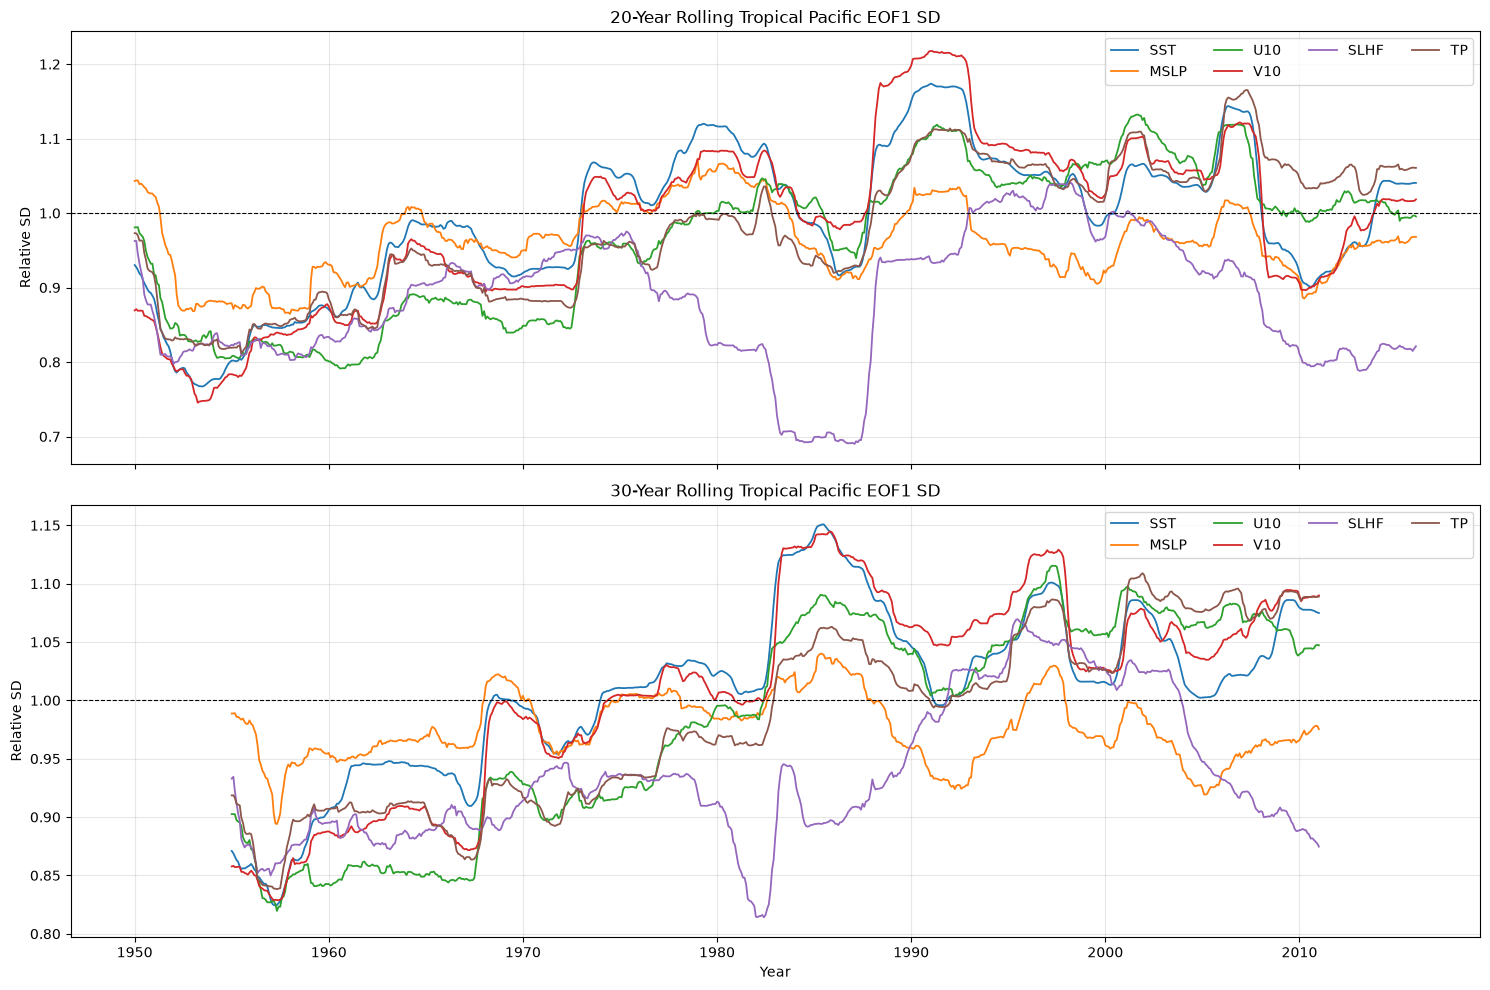

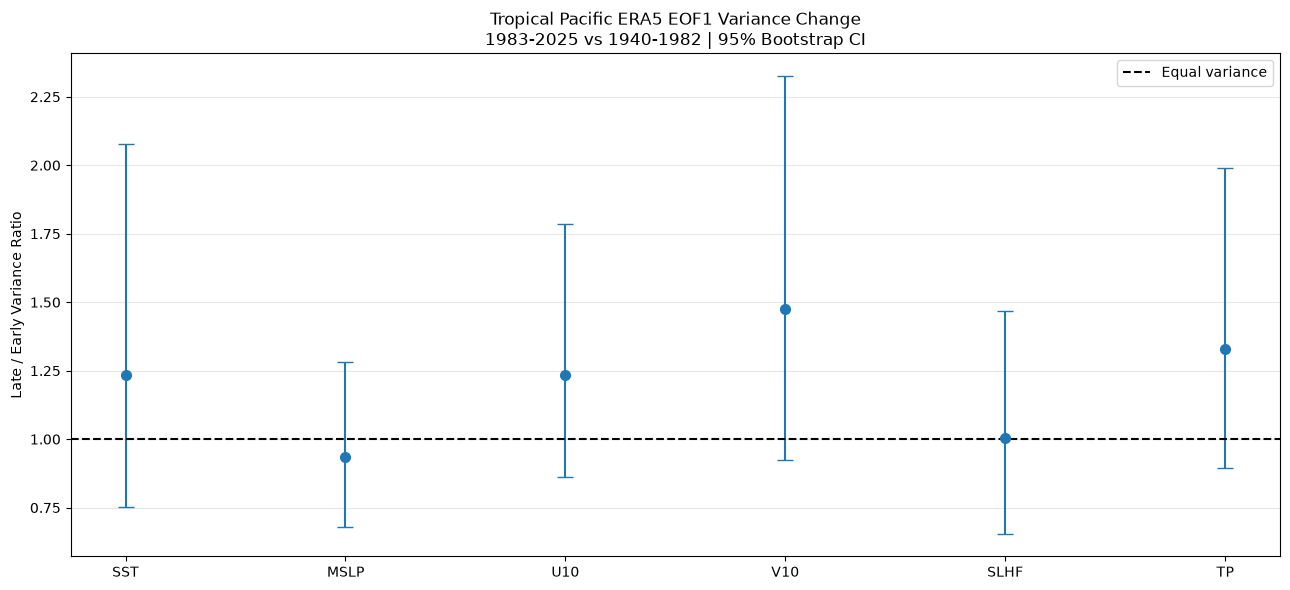

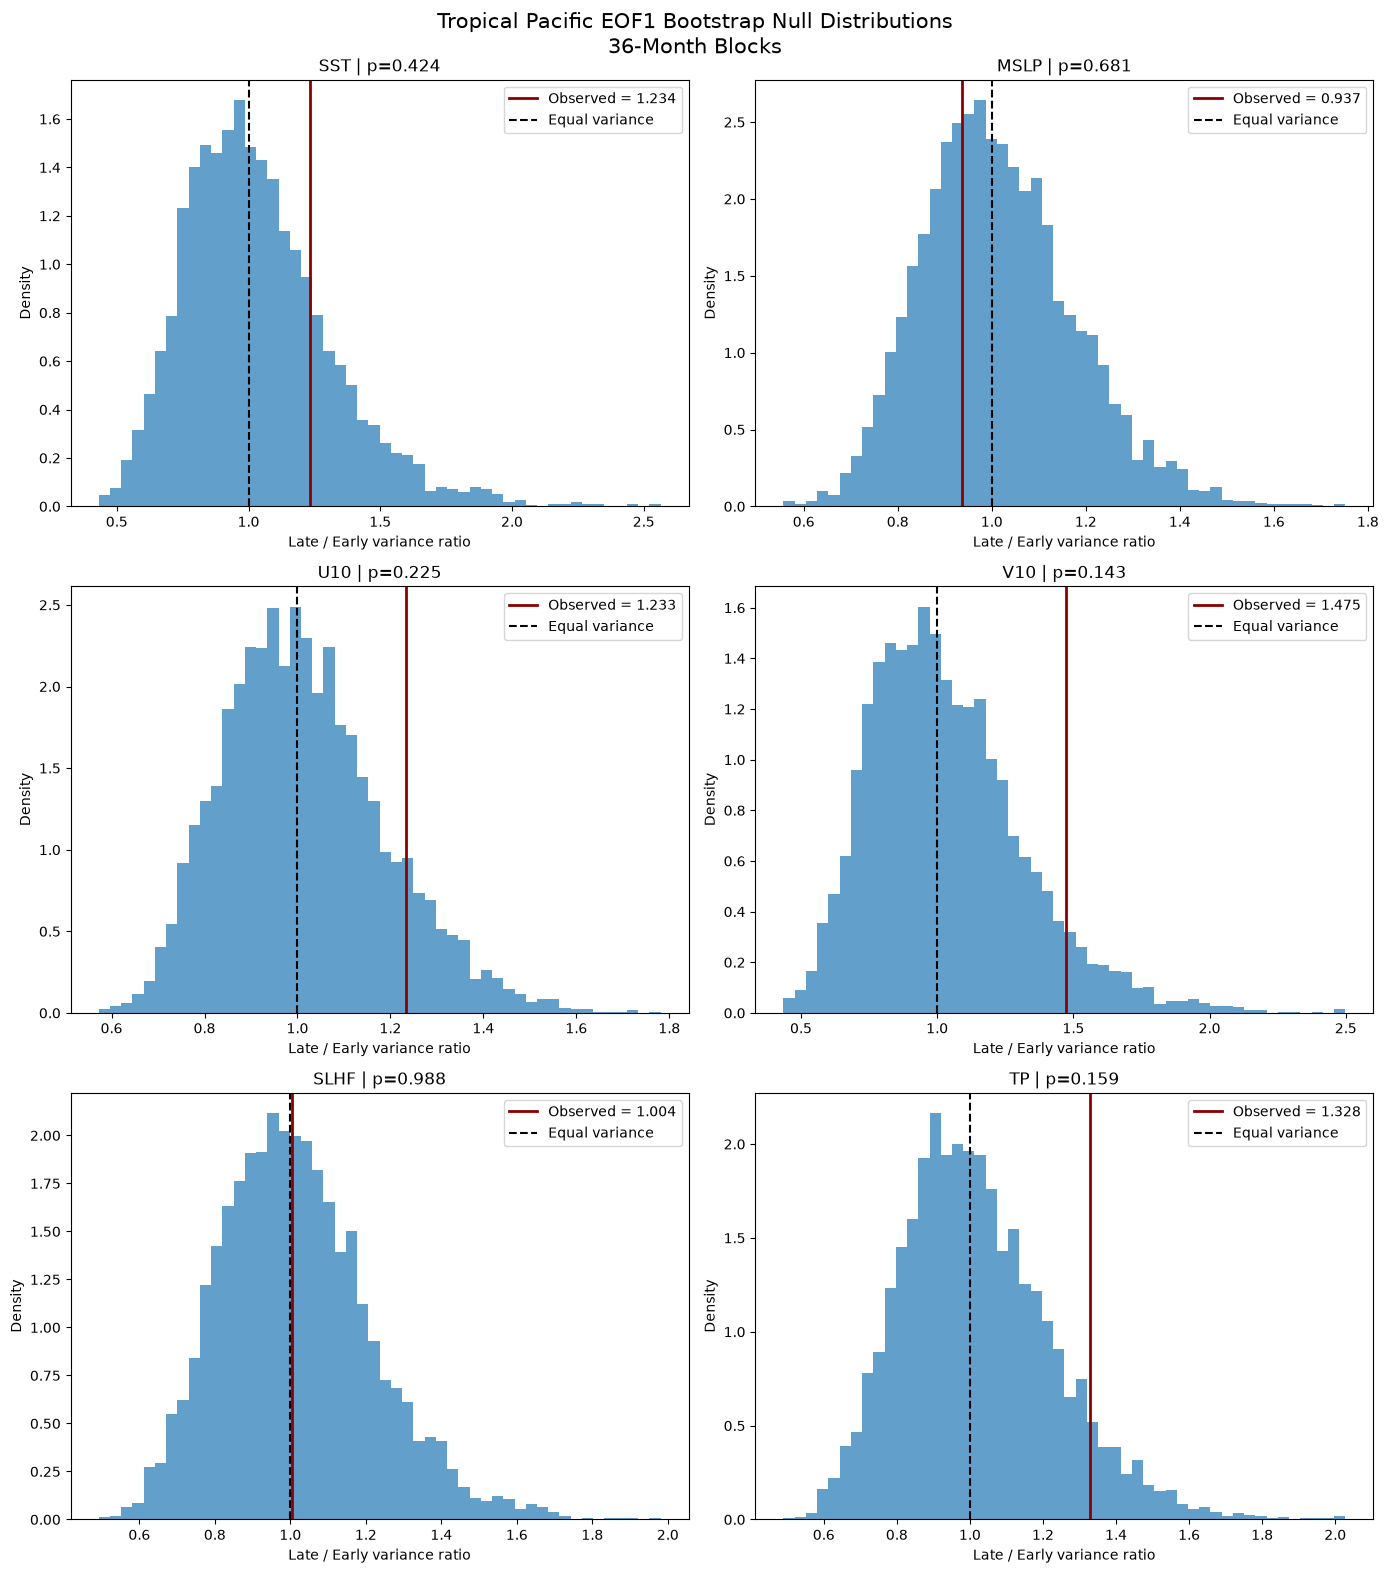


ERA5 TROPICAL PACIFIC VARIABILITY ANALYSIS COMPLETE

SST
  EOF1 explained variance: 49.99%
  Niño 3.4 correlation: 0.966
  Variance ratio: 1.2335
  Variance change: +23.35%
  95% CI: [0.7513, 2.0769]
  p-value: 0.4237
  No significant change detected

MSLP
  EOF1 explained variance: 38.17%
  Niño 3.4 correlation: 0.672
  Variance ratio: 0.9368
  Variance change: -6.32%
  95% CI: [0.6812, 1.2815]
  p-value: 0.6815
  No significant change detected

U10
  EOF1 explained variance: 25.47%
  Niño 3.4 correlation: 0.670
  Variance ratio: 1.2330
  Variance change: +23.30%
  95% CI: [0.8627, 1.7845]
  p-value: 0.2250
  No significant change detected

V10
  EOF1 explained variance: 17.49%
  Niño 3.4 correlation: 0.825
  Variance ratio: 1.4747
  Variance change: +47.47%
  95% CI: [0.9230, 2.3251]
  p-value: 0.1426
  No significant change detected

SLHF
  EOF1 explained variance: 13.52%
  Niño 3.4 correlation: 0.654
  Variance ratio: 1.0036
  Variance change: +0.36%
  95% CI: [0.6556, 1.4665]
  p

In [7]:

import gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 TROPICAL PACIFIC EOF1 VARIABILITY ANALYSIS
# SST, MSLP, U10, V10, SLHF, TP
# 1940-2025 | Circular moving-block bootstrap
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_START, EARLY_END = 1940, 1982
LATE_START, LATE_END = 1983, 2025

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

COARSEN_FACTOR = 8  # 0.25 degrees -> approx. 2 degrees

BLOCK_LENGTHS = [24, 36, 60, 84, 120]
PRIMARY_BLOCK = 36

N_BOOTSTRAP = 5000
RANDOM_SEED = 42

DATA_DIR = Path("data/era5/era5_global")
INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

OUTPUT_DIR = Path(
    "derived_data/era5/tropical_pacific_variability"
)

FIG_DIR = Path(
    "figures/era5_tropical_pacific_variability"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


VARIABLES = {
    "SST": {
        "file": "era5_sea_surface_temperature_1940_2025.nc",
        "variable": "sst",
        "units": "degC",
    },
    "MSLP": {
        "file": "era5_mean_sea_level_pressure_1940_2025.nc",
        "variable": "msl",
        "units": "hPa",
    },
    "U10": {
        "file": "era5_10m_u_component_of_wind_1940_2025.nc",
        "variable": "u10",
        "units": "m/s",
    },
    "V10": {
        "file": "era5_10m_v_component_of_wind_1940_2025.nc",
        "variable": "v10",
        "units": "m/s",
    },
    "SLHF": {
        "file": "era5_surface_latent_heat_flux_1940_2025.nc",
        "variable": "slhf",
        "units": "W/m2",
    },
    "TP": {
        "file": "era5_total_precipitation_1940_2025.nc",
        "variable": "tp",
        "units": "mm/day",
    },
}


# ============================================================
# 1. LOAD NINO 3.4 INDEX
# ============================================================

print("=" * 70)
print("ERA5 TROPICAL PACIFIC EOF1 VARIABILITY ANALYSIS")
print("=" * 70)

with xr.open_dataset(INDEX_FILE) as ds:

    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M"),
    name="Nino34"
).sort_index()

expected_months = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert nino_series.index.equals(expected_months)
assert np.isfinite(nino_series.values).all()

print("Niño 3.4 months:", len(nino_series))

# ============================================================
# 2. LOAD TROPICAL PACIFIC ERA5 VARIABLE
# ============================================================

def load_field(name, config):

    path = DATA_DIR / config["file"]

    print(f"\nLoading {name}: {path}")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[config["variable"]]

        units = da.attrs.get("units", "").strip()

        # Convert longitude to 0-360
        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        # Select tropical Pacific before loading
        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            ),
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        # Coarsen to approximately 2 degrees
        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        # ----------------------------------------
        # Unit conversions
        # ----------------------------------------

        if name in ("SST"):

            if units in ("K", "kelvin", "Kelvin"):
                da = da - 273.15

            elif units not in (
                "degC", "C", "celsius", "degrees_C"
            ):
                raise ValueError(
                    f"Unexpected {name} units: {units}"
                )

        elif name == "MSLP":

            if units == "Pa":
                da = da / 100.0

            elif units not in ("hPa", "mbar"):
                raise ValueError(
                    f"Unexpected MSLP units: {units}"
                )

        elif name == "SLHF":

            if units in (
                "J m**-2",
                "J m**-2 day**-1",
                "J/m2",
                "J/m2/day",
                "J m-2",
                "J m-2 day-1"
            ):
                # ERA5 monthly averaged daily accumulations
                # Convert J/m2/day to W/m2
                da = da / 86400.0

            elif units not in (
                "W m**-2", "W/m2", "W m-2"
            ):
                raise ValueError(
                    f"Unexpected SLHF units: {units}"
                )

        elif name == "TP":

            if units in ("m", "m/day", "m day-1"):
                # Convert m/day to mm/day
                da = da * 1000.0

            elif units not in ("mm/day", "mm day-1"):
                raise ValueError(
                    f"Unexpected TP units: {units}"
                )

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

        da.attrs["units"] = config["units"]

    months = pd.to_datetime(
        da.time.values
    ).to_period("M")

    assert months.equals(expected_months), (
        f"{name}: missing or unexpected months"
    )

    print("Tropical Pacific shape:", da.shape)
    print("Units:", config["units"])

    return da


# ============================================================
# 3. CALCULATE TROPICAL PACIFIC EOF1
# ============================================================

def calculate_eof1(da, name):

    print(f"\nCalculating {name} EOF1...")

    # Remove monthly seasonal climatology
    climatology = da.groupby(
        "time.month"
    ).mean("time")

    anomalies = (
        da.groupby("time.month") - climatology
    )

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(
        nt, ny * nx
    )

    # Exclude cells containing missing observations
    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(
        np.float32, copy=True
    )

    if X.shape[1] < 2:
        raise ValueError(
            f"Insufficient valid cells for {name}"
        )

    # Remove full-period linear trend at each cell
    X = detrend(
        X,
        axis=0,
        type="linear"
    ).astype(np.float32)

    # Square-root cosine latitude weights
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0,
            None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    positive = weights > 1e-8

    X = X[:, positive]
    weights = weights[positive]

    valid_indices = np.flatnonzero(valid)[positive]

    # Apply EOF area weighting
    X_weighted = X * weights

    # Fit EOF1 over the entire record
    pca = PCA(
        n_components=1,
        svd_solver="randomized",
        random_state=42
    )

    pc = pca.fit_transform(
        X_weighted
    )[:, 0]

    explained = (
        pca.explained_variance_ratio_[0] * 100
    )

    # Reconstruct physical-space EOF
    eof_flat = np.full(
        ny * nx,
        np.nan,
        dtype=np.float32
    )

    eof_flat[valid_indices] = (
        pca.components_[0] / weights
    )

    eof_map = eof_flat.reshape(ny, nx)

    # ----------------------------------------
    # Align EOF and PC signs with Niño 3.4
    # ----------------------------------------

    months = pd.to_datetime(
        anomalies.time.values
    ).to_period("M")

    pc_series = pd.Series(
        pc,
        index=months
    )

    common = pc_series.index.intersection(
        nino_series.index
    )

    a = pc_series.loc[common].to_numpy()
    b = nino_series.loc[common].to_numpy()

    finite = np.isfinite(a) & np.isfinite(b)

    original_r = np.corrcoef(
        a[finite],
        b[finite]
    )[0, 1]

    sign = -1 if original_r < 0 else 1

    # Approach 3: flip EOF and PC together, once
    pc = pc * sign
    eof_map = eof_map * sign

    aligned_r = original_r * sign
    flipped = sign == -1

    # Standardise PC over full period
    pc = (
        pc - pc.mean()
    ) / pc.std(ddof=1)

    series = pd.Series(
        pc,
        index=months,
        name=name
    )

    print(
        f"{name}: EOF1 explained variance = "
        f"{explained:.2f}%"
    )

    print(
        f"  Original Niño r={original_r:+.3f}, "
        f"aligned r={aligned_r:+.3f}, "
        f"flipped={flipped}"
    )

    return series, eof_map, {
        "explained": explained,
        "original_r": original_r,
        "aligned_r": aligned_r,
        "flipped": flipped,
    }


# ============================================================
# 4. CALCULATE ALL SEVEN EOF1 PCs
# ============================================================

pc_series = {}
eof_maps = {}
metadata = {}

for name, config in VARIABLES.items():

    da = load_field(name, config)

    series, eof_map, info = calculate_eof1(
        da, name
    )

    pc_series[name] = series

    eof_maps[name] = {
        "pattern": eof_map,
        "latitude": da.latitude.values.copy(),
        "longitude": da.longitude.values.copy(),
    }

    metadata[name] = info

    del da
    gc.collect()


pcs = pd.concat(
    pc_series.values(),
    axis=1
).sort_index()

assert pcs.index.equals(expected_months)
assert np.isfinite(pcs.values).all()

pcs.to_csv(
    OUTPUT_DIR / "tropical_pacific_eof1_monthly_pcs.csv"
)

print("\nAll seven EOF1 PCs calculated.")
print(pcs.head())

# ============================================================
# 5. CIRCULAR MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng, size=None):

    x = np.asarray(x, dtype=float)

    n = len(x)

    if size is None:
        size = n

    n_blocks = int(np.ceil(size / block))

    starts = rng.integers(
        0,
        n,
        size=n_blocks
    )

    indices = (
        starts[:, None]
        + np.arange(block)[None, :]
    ) % n

    return x[indices.ravel()[:size]]


def variance_ratio_test(
    early,
    late,
    block,
    n_bootstrap=5000,
    seed=42
):

    rng = np.random.default_rng(seed)

    early = np.asarray(early, dtype=float)
    late = np.asarray(late, dtype=float)

    n_early = len(early)
    n_late = len(late)

    observed = (
        np.var(late, ddof=1) /
        np.var(early, ddof=1)
    )

    bootstrap_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Approximate null: pooled, centred process
    pooled = np.concatenate([
        early - early.mean(),
        late - late.mean()
    ])

    for i in range(n_bootstrap):

        # Confidence interval:
        # resample early and late separately
        e = block_sample(
            early, block, rng, n_early
        )

        l = block_sample(
            late, block, rng, n_late
        )

        bootstrap_ratios[i] = (
            np.var(l, ddof=1) /
            np.var(e, ddof=1)
        )

        # Null distribution:
        # both samples from pooled process
        e0 = block_sample(
            pooled, block, rng, n_early
        )

        l0 = block_sample(
            pooled, block, rng, n_late
        )

        null_ratios[i] = (
            np.var(l0, ddof=1) /
            np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        bootstrap_ratios,
        [0.025, 0.975]
    )

    # Two-sided log variance-ratio statistic
    observed_stat = abs(np.log(observed))
    null_stat = np.abs(np.log(null_ratios))

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return {
        "observed": observed,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
        "bootstrap_ratios": bootstrap_ratios,
        "null_ratios": null_ratios,
    }


# ============================================================
# 6. RUN BOOTSTRAP TESTS
# ============================================================

results = {}
rows = []

for name in VARIABLES:

    early = pcs.loc[
        f"{EARLY_START}-01":
        f"{EARLY_END}-12",
        name
    ].to_numpy()

    late = pcs.loc[
        f"{LATE_START}-01":
        f"{LATE_END}-12",
        name
    ].to_numpy()

    early_std = np.std(early, ddof=1)
    late_std = np.std(late, ddof=1)

    for block in BLOCK_LENGTHS:

        print(
            f"Testing {name}: "
            f"{block}-month blocks..."
        )

        result = variance_ratio_test(
            early,
            late,
            block,
            N_BOOTSTRAP,
            RANDOM_SEED + block
        )

        results[(name, block)] = result

        rows.append({
            "Variable": name,
            "Block months": block,
            "Early SD": early_std,
            "Late SD": late_std,
            "Variance ratio": result["observed"],
            "Variance change (%)": (
                (result["observed"] - 1) * 100
            ),
            "CI lower": result["ci_low"],
            "CI upper": result["ci_high"],
            "p value": result["p_value"],
            "EOF1 variance (%)": metadata[name]["explained"],
            "Niño 3.4 r": metadata[name]["aligned_r"],
            "Original r": metadata[name]["original_r"],
            "Flipped": metadata[name]["flipped"],
        })

summary = pd.DataFrame(rows)

summary.to_csv(
    OUTPUT_DIR / "tropical_pacific_bootstrap_results.csv",
    index=False
)

print("\n" + "=" * 70)
print("TROPICAL PACIFIC EOF1 BOOTSTRAP RESULTS")
print("=" * 70)

print(
    summary.round(4).to_string(index=False)
)

# ============================================================
# 7. PRIMARY RESULTS
# ============================================================

primary = summary[
    summary["Block months"] == PRIMARY_BLOCK
].set_index("Variable").loc[list(VARIABLES)]

print("\n" + "=" * 70)
print("PRIMARY RESULTS: 36-MONTH BLOCKS")
print("=" * 70)

print(
    primary[
        [
            "EOF1 variance (%)",
            "Niño 3.4 r",
            "Early SD",
            "Late SD",
            "Variance ratio",
            "Variance change (%)",
            "CI lower",
            "CI upper",
            "p value",
        ]
    ].round(4)
)

# ============================================================
# 8. DECADAL VARIABILITY
# ============================================================

decadal_rows = []

for name in VARIABLES:

    for start in range(
        START_YEAR,
        END_YEAR + 1,
        10
    ):

        end = min(start + 9, END_YEAR)

        subset = pcs.loc[
            f"{start}-01":f"{end}-12",
            name
        ]

        decadal_rows.append({
            "Variable": name,
            "Period": f"{start}-{end}",
            "Months": len(subset),
            "Relative SD": subset.std(ddof=1),
            "Relative variance": subset.var(ddof=1),
        })

decadal = pd.DataFrame(decadal_rows)

decadal.to_csv(
    OUTPUT_DIR / "tropical_pacific_decadal_variability.csv",
    index=False
)

# ============================================================
# 9. ROLLING STANDARD DEVIATIONS
# ============================================================

rolling_20 = pcs.rolling(
    20 * 12,
    center=True,
    min_periods=20 * 12
).std()

rolling_30 = pcs.rolling(
    30 * 12,
    center=True,
    min_periods=30 * 12
).std()

# ============================================================
# 10. PLOT EOF1 SPATIAL PATTERNS
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 15),
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    },
    constrained_layout=True
)

axes = axes.ravel()

for i, name in enumerate(VARIABLES):

    ax = axes[i]
    info = eof_maps[name]
    meta = metadata[name]

    pattern = info["pattern"]

    vmax = np.nanmax(np.abs(pattern))

    im = ax.pcolormesh(
        info["longitude"],
        info["latitude"],
        pattern,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto"
    )

    ax.coastlines(resolution="110m")

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    ax.set_title(
        f"{name} EOF1 | "
        f"{meta['explained']:.1f}% variance\n"
        f"Niño r={meta['aligned_r']:+.2f}"
        + (" | flipped" if meta["flipped"] else "")
    )

    fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        shrink=0.8,
        pad=0.05,
        label="EOF loading"
    )

plt.savefig(
    FIG_DIR / "tropical_pacific_eof1_maps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. PLOT DECADAL VARIABILITY
# ============================================================

fig, ax = plt.subplots(figsize=(15, 6))

for name in VARIABLES:

    subset = decadal[
        decadal["Variable"] == name
    ]

    ax.plot(
        subset["Period"],
        subset["Relative SD"],
        marker="o",
        linewidth=1.6,
        label=name
    )

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Full-period SD"
)

ax.set_title(
    "Decadal Variability of Tropical Pacific EOF1 Modes\n"
    "ERA5 | 1940-2025"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=4)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tropical_pacific_decadal_variability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. PLOT ROLLING VARIABILITY
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

dates = pcs.index.to_timestamp()

for name in VARIABLES:

    axes[0].plot(
        dates,
        rolling_20[name],
        label=name,
        linewidth=1.3
    )

    axes[1].plot(
        dates,
        rolling_30[name],
        label=name,
        linewidth=1.3
    )

for ax, years in zip(axes, [20, 30]):

    ax.axhline(
        1,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(
        f"{years}-Year Rolling Tropical Pacific EOF1 SD"
    )

    ax.set_ylabel("Relative SD")
    ax.grid(alpha=0.3)
    ax.legend(ncol=4)

axes[-1].set_xlabel("Year")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tropical_pacific_rolling_variability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. PLOT VARIANCE RATIOS WITH 95% CI
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

names = list(primary.index)
x = np.arange(len(names))

ratios = primary["Variance ratio"].to_numpy()
lower = primary["CI lower"].to_numpy()
upper = primary["CI upper"].to_numpy()

ax.errorbar(
    x,
    ratios,
    yerr=[
        ratios - lower,
        upper - ratios
    ],
    fmt="o",
    capsize=6,
    markersize=7
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Equal variance"
)

ax.set_xticks(x)
ax.set_xticklabels(names)

ax.set_ylabel("Late / Early Variance Ratio")

ax.set_title(
    "Tropical Pacific ERA5 EOF1 Variance Change\n"
    "1983-2025 vs 1940-1982 | 95% Bootstrap CI"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tropical_pacific_variance_ratio_ci.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. PLOT BOOTSTRAP NULL DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 16)
)

axes = axes.ravel()

for i, name in enumerate(VARIABLES):

    ax = axes[i]

    result = results[(name, PRIMARY_BLOCK)]

    observed = result["observed"]

    ax.hist(
        result["null_ratios"],
        bins=50,
        density=True,
        alpha=0.7
    )

    ax.axvline(
        observed,
        color="darkred",
        linewidth=2,
        label=f"Observed = {observed:.3f}"
    )

    ax.axvline(
        1,
        color="black",
        linestyle="--",
        label="Equal variance"
    )

    ax.set_title(
        f"{name} | p={result['p_value']:.3f}"
    )

    ax.set_xlabel("Late / Early variance ratio")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    "Tropical Pacific EOF1 Bootstrap Null Distributions\n"
    f"{PRIMARY_BLOCK}-Month Blocks",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tropical_pacific_bootstrap_null_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. SAVE EOF MAPS AS NETCDF
# ============================================================

for name, info in eof_maps.items():

    eof_da = xr.DataArray(
        info["pattern"],
        coords={
            "latitude": info["latitude"],
            "longitude": info["longitude"],
        },
        dims=["latitude", "longitude"],
        name=f"{name.lower()}_eof1"
    )

    eof_da.attrs["description"] = (
        "Tropical Pacific EOF1 physical-space loading; "
        "sign-aligned with Niño 3.4; "
        "weighted PCA of detrended monthly anomalies"
    )

    eof_da.attrs["explained_variance_percent"] = (
        float(metadata[name]["explained"])
    )

    eof_da.attrs["nino34_correlation"] = (
        float(metadata[name]["aligned_r"])
    )

    eof_da.attrs["original_correlation"] = (
        float(metadata[name]["original_r"])
    )

    eof_da.attrs["flipped"] = str(
        metadata[name]["flipped"]
    )

    eof_da.to_netcdf(
        OUTPUT_DIR / f"{name.lower()}_tropical_pacific_eof1.nc"
    )

# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ERA5 TROPICAL PACIFIC VARIABILITY ANALYSIS COMPLETE")
print("=" * 70)

for name in VARIABLES:

    row = primary.loc[name]

    print(f"\n{name}")

    print(
        f"  EOF1 explained variance: "
        f"{row['EOF1 variance (%)']:.2f}%"
    )

    print(
        f"  Niño 3.4 correlation: "
        f"{row['Niño 3.4 r']:.3f}"
    )

    print(
        f"  Variance ratio: "
        f"{row['Variance ratio']:.4f}"
    )

    print(
        f"  Variance change: "
        f"{row['Variance change (%)']:+.2f}%"
    )

    print(
        f"  95% CI: "
        f"[{row['CI lower']:.4f}, "
        f"{row['CI upper']:.4f}]"
    )

    print(
        f"  p-value: "
        f"{row['p value']:.4f}"
    )

    if row["p value"] < 0.05:
        print("  Significant at 5% (exploratory)")
    else:
        print("  No significant change detected")

print("\nData outputs:")
print(OUTPUT_DIR.resolve())

print("\nFigures:")
print(FIG_DIR.resolve())

print("=" * 70)


ERA5 ENSO ATMOSPHERIC RESPONSE CHANGE

Loading V10: data\era5\era5_global\era5_10m_v_component_of_wind_1940_2025.nc
Shape: (1032, 20, 80)
Valid cells: 1600


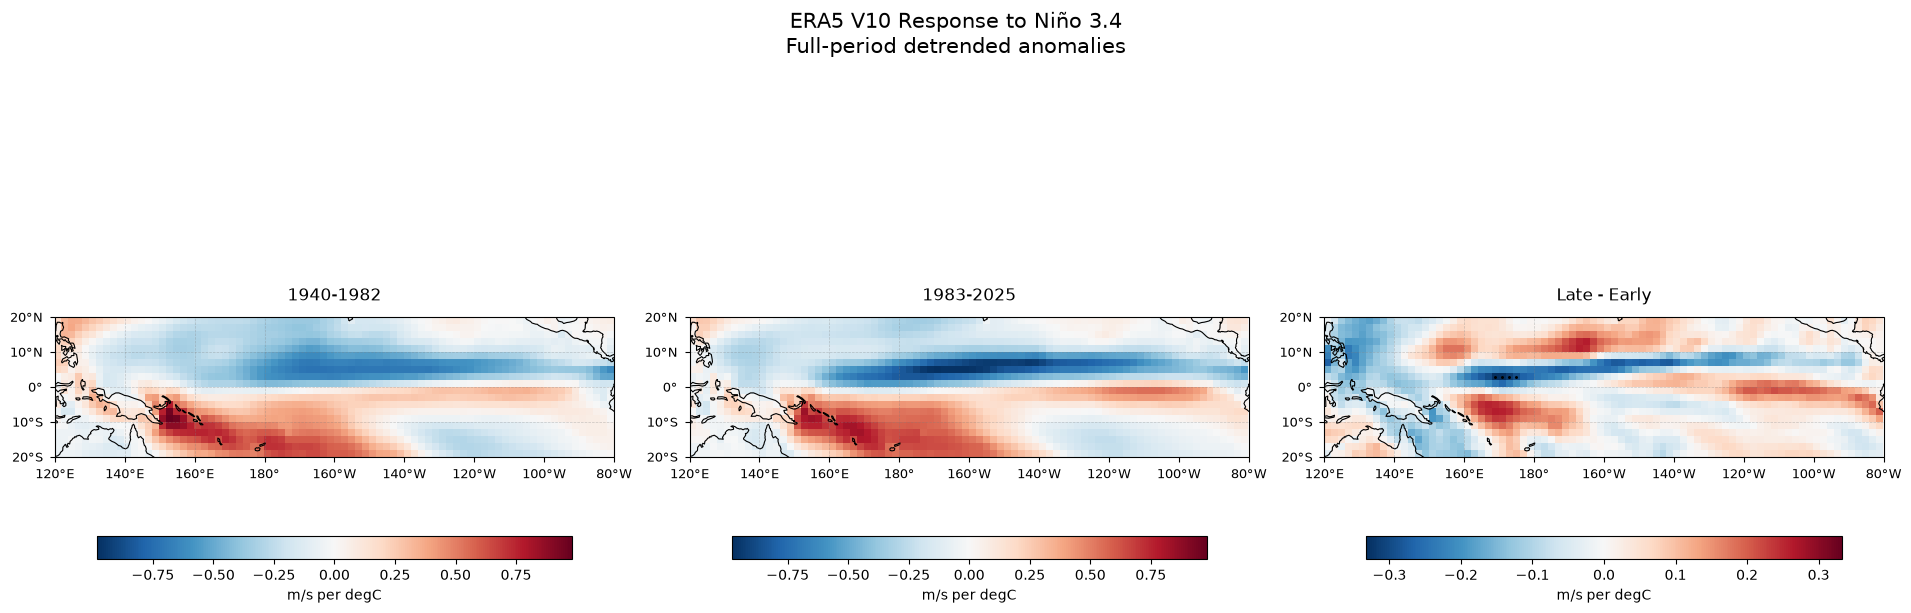


V10
FDR-significant cells: 4
Valid cells: 1600

Loading TP: data\era5\era5_global\era5_total_precipitation_1940_2025.nc
Shape: (1032, 20, 80)
Valid cells: 1600


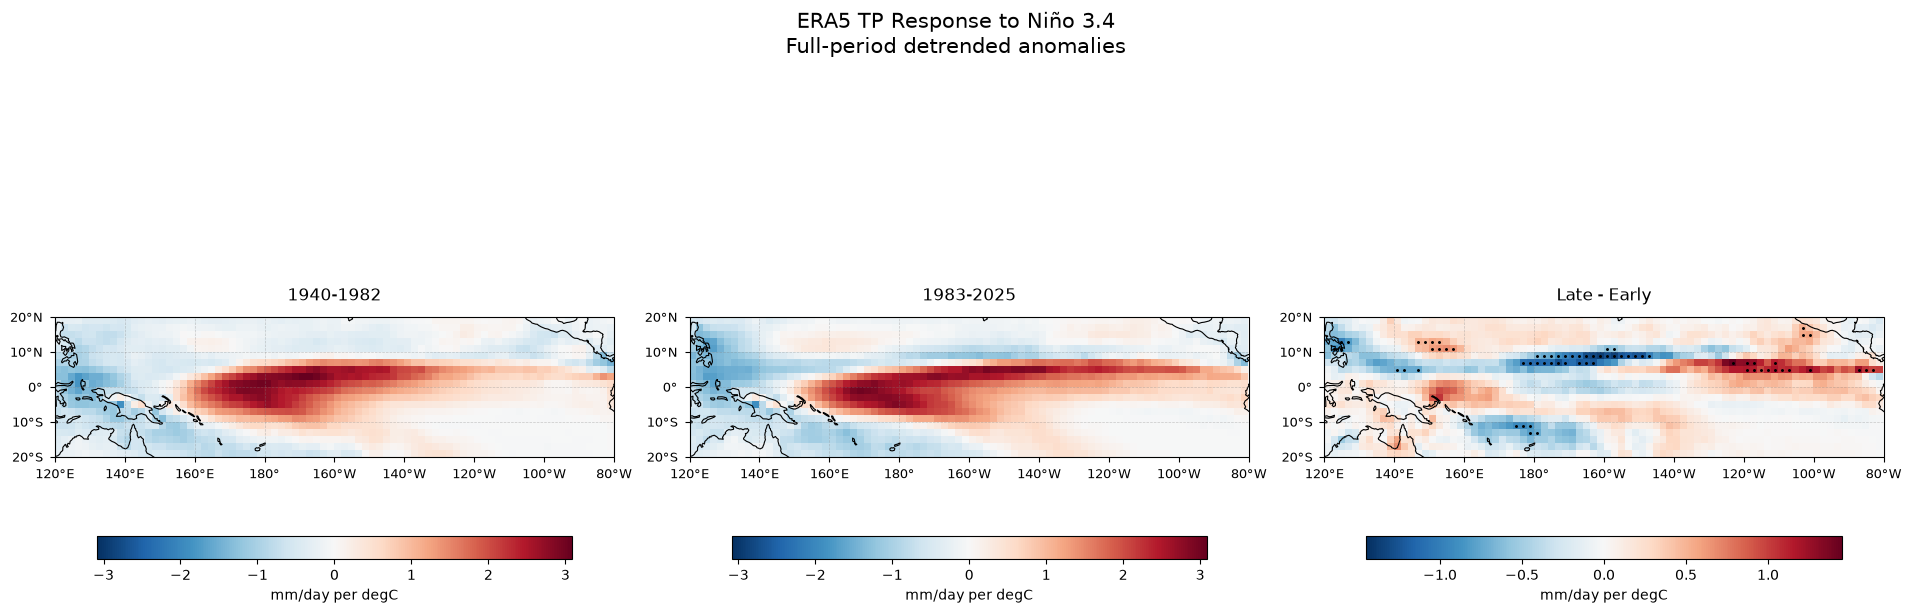


TP
FDR-significant cells: 67
Valid cells: 1600

ENSO RESPONSE ANALYSIS COMPLETE
Data: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\enso_response_change
Figures: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_enso_response_change


In [12]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from scipy.signal import detrend
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# ============================================================
# ERA5 ENSO ATMOSPHERIC RESPONSE CHANGE
# V10 and Total Precipitation | 1940-2025
#
# Compare regression onto detrended Nino 3.4:
#   Early: 1940-1982
#   Late:  1983-2025
#
# Full-period monthly climatology and linear detrending
# HAC significance test + spatial FDR correction
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_END = 1982
LATE_START = 1983

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

COARSEN_FACTOR = 8

HAC_LAGS = 36
ALPHA = 0.05

DATA_DIR = Path("data/era5/era5_global")
INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

OUTPUT_DIR = Path(
    "derived_data/era5/enso_response_change"
)
FIG_DIR = Path(
    "figures/era5_enso_response_change"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

VARIABLES = {
    "V10": {
        "file": "era5_10m_v_component_of_wind_1940_2025.nc",
        "variable": "v10",
        "units": "m/s per degC",
    },
    "TP": {
        "file": "era5_total_precipitation_1940_2025.nc",
        "variable": "tp",
        "units": "mm/day per degC",
    },
}

# ============================================================
# 1. LOAD NINO 3.4
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds:
    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M")
).sort_index()

expected_months = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert nino_series.index.equals(expected_months)
assert np.isfinite(nino_series.values).all()

nino_values = nino_series.to_numpy()

# ============================================================
# 2. LOAD AND PREPROCESS ERA5 FIELDS
# ============================================================

def load_anomalies(name, config):

    path = DATA_DIR / config["file"]

    print(f"\nLoading {name}: {path}")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[config["variable"]]

        units = da.attrs.get("units", "").strip()

        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            ),
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        if name == "TP":
            if units in ("m", "m/day", "m day-1"):
                # ERA5 monthly averaged daily accumulations
                da = da * 1000.0
            elif units not in ("mm/day", "mm day-1"):
                raise ValueError(
                    f"Unexpected TP units: {units}"
                )

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

    # Align by calendar month, not exact hour
    months = pd.to_datetime(
        da.time.values
    ).to_period("M")

    assert months.equals(expected_months), (
        f"{name}: monthly coordinates do not match"
    )

    # Remove full-period seasonal cycle
    climatology = da.groupby("time.month").mean("time")
    anomalies = da.groupby("time.month") - climatology

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(nt, -1)

    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(np.float64)

    # Remove full-period linear trend
    X = detrend(X, axis=0, type="linear")

    full = np.full(
        (nt, ny * nx),
        np.nan,
        dtype=np.float32
    )

    full[:, valid] = X.astype(np.float32)

    result = xr.DataArray(
        full.reshape(nt, ny, nx),
        coords={
            "time": expected_months.to_timestamp(),
            "latitude": anomalies.latitude.values,
            "longitude": anomalies.longitude.values,
        },
        dims=["time", "latitude", "longitude"],
        name=name,
    )

    print("Shape:", result.shape)
    print("Valid cells:", valid.sum())

    return result

# ============================================================
# 3. REGRESSION AND HAC TEST
# ============================================================

def regression_change_test(anomalies, nino_values):

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    Y = anomalies.values.reshape(nt, -1)

    years = expected_months.year.to_numpy()

    D = (years >= LATE_START).astype(float)

    N = nino_values.astype(float)

    # Interaction regression:
    # Y = a + b*N + c*D + d*(N*D) + error
    #
    # b = early slope
    # b+d = late slope
    # d = late - early slope

    design = np.column_stack([
        np.ones(nt),
        N,
        D,
        N * D
    ])

    valid = np.isfinite(Y).all(axis=0)

    Y_valid = Y[:, valid].astype(np.float64)

    # OLS coefficients for all grid cells
    XtX_inv = np.linalg.inv(design.T @ design)
    coefficients = (
        XtX_inv @ design.T @ Y_valid
    )

    residuals = (
        Y_valid - design @ coefficients
    )

    # Newey-West HAC covariance for interaction term
    # Vectorised across spatial grid cells
    scores = (
        design[:, :, None] *
        residuals[:, None, :]
    )

    n_cells = Y_valid.shape[1]

    cov_scores = np.einsum(
        "tip,tjp->ijp",
        scores, scores,
        optimize=True
    )

    for lag in range(1, HAC_LAGS + 1):

        weight = 1 - lag / (HAC_LAGS + 1)

        gamma = np.einsum(
            "tip,tjp->ijp",
            scores[lag:],
            scores[:-lag],
            optimize=True
        )

        cov_scores += weight * (
            gamma + gamma.transpose(1, 0, 2)
        )

    # Covariance of OLS coefficients
    covariance = np.einsum(
        "ai,ijp,jb->abp",
        XtX_inv,
        cov_scores,
        XtX_inv,
        optimize=True
    )

    delta = coefficients[3]

    se_delta = np.sqrt(
        np.maximum(covariance[3, 3], 0)
    )

    z = np.divide(
        delta,
        se_delta,
        out=np.full_like(delta, np.nan),
        where=se_delta > 0
    )

    p_values = 2 * norm.sf(np.abs(z))

    # FDR correction over spatial grid
    significant = np.zeros(
        n_cells, dtype=bool
    )

    finite_p = np.isfinite(p_values)

    if finite_p.any():
        significant[finite_p] = multipletests(
            p_values[finite_p],
            alpha=ALPHA,
            method="fdr_bh"
        )[0]

    # Restore spatial fields
    def restore(values):
        out = np.full(ny * nx, np.nan)
        out[valid] = values
        return out.reshape(ny, nx)

    early = restore(coefficients[1])
    late = restore(
        coefficients[1] + coefficients[3]
    )
    difference = restore(delta)
    p_map = restore(p_values)

    sig_map = np.zeros(ny * nx, dtype=bool)
    sig_map[valid] = significant
    sig_map = sig_map.reshape(ny, nx)

    return {
        "early": early,
        "late": late,
        "difference": difference,
        "p": p_map,
        "significant": sig_map,
    }

# ============================================================
# 4. PLOT REGRESSION MAPS
# WITH LATITUDE AND LONGITUDE AXES
# ============================================================

import cartopy.mpl.ticker as cticker
from matplotlib.ticker import FixedLocator

def plot_regression_maps(result, da, name, units):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 6),
        subplot_kw={
            "projection": ccrs.PlateCarree(
                central_longitude=180
            )
        },
        constrained_layout=True
    )

    lon = da.longitude.values
    lat = da.latitude.values

    # Same colour scale for early and late
    response_max = max(
        np.nanmax(np.abs(result["early"])),
        np.nanmax(np.abs(result["late"]))
    )

    difference_max = np.nanmax(
        np.abs(result["difference"])
    )

    # Geographic gridline locations
    lon_ticks = np.arange(120, 281, 20)
    lat_ticks = np.arange(-20, 21, 10)

    for ax, key, title in zip(
        axes,
        ["early", "late", "difference"],
        [
            "1940-1982",
            "1983-2025",
            "Late - Early"
        ]
    ):

        vmax = (
            difference_max
            if key == "difference"
            else response_max
        )

        im = ax.pcolormesh(
            lon,
            lat,
            result[key],
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            shading="auto"
        )

        ax.coastlines(
            resolution="110m",
            linewidth=0.8
        )

        ax.set_extent(
            [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
            crs=ccrs.PlateCarree()
        )

        
        # ----------------------------------------
        # LATITUDE AND LONGITUDE AXES
        # Pacific-centred projection
        # ----------------------------------------

        from cartopy.mpl.ticker import (
            LongitudeFormatter,
            LatitudeFormatter
        )

        # Geographic longitudes in 0-360 convention
        lon_ticks = np.arange(120, 281, 20)

        # Convert to coordinates of the Pacific-centred
        # PlateCarree projection (-180 to +180 relative to 180)
        lon_positions = (
            (lon_ticks - 180 + 180) % 360
        ) - 180

        lat_ticks = np.arange(-20, 21, 10)

        # Set ticks explicitly in the map projection
        ax.set_xticks(
            lon_positions,
            crs=ccrs.PlateCarree(central_longitude=180)
        )

        ax.set_yticks(
            lat_ticks,
            crs=ccrs.PlateCarree()
        )

        # Format longitudes as E/W using original
        # geographic longitude values
        def format_pacific_lon(x, pos=None):

            geographic_lon = (x + 180) % 360

            if np.isclose(geographic_lon, 180):
                return "180°"

            if geographic_lon < 180:
                return f"{geographic_lon:.0f}°E"

            return f"{360 - geographic_lon:.0f}°W"


        def format_lat(y, pos=None):

            if np.isclose(y, 0):
                return "0°"

            if y > 0:
                return f"{y:.0f}°N"

            return f"{abs(y):.0f}°S"


        from matplotlib.ticker import FuncFormatter

        ax.xaxis.set_major_formatter(
            FuncFormatter(format_pacific_lon)
        )

        ax.yaxis.set_major_formatter(
            FuncFormatter(format_lat)
        )

        ax.tick_params(
            axis="both",
            labelsize=9,
            pad=5
        )

        # Gridlines without automatic labels
        ax.gridlines(
            crs=ccrs.PlateCarree(),
            xlocs=lon_ticks,
            ylocs=lat_ticks,
            draw_labels=False,
            linewidth=0.5,
            color="grey",
            alpha=0.4,
            linestyle="--"
        )


        # ----------------------------------------
        # TITLE
        # ----------------------------------------

        ax.set_title(
            title,
            fontsize=12,
            pad=12
        )

        # ----------------------------------------
        # STATISTICAL SIGNIFICANCE
        # ----------------------------------------

        if key == "difference":

            yy, xx = np.meshgrid(
                lat,
                lon,
                indexing="ij"
            )

            sig = result["significant"]

            ax.scatter(
                xx[sig],
                yy[sig],
                s=5,
                color="black",
                marker=".",
                transform=ccrs.PlateCarree(),
                zorder=5
            )

        # ----------------------------------------
        # COLOURBAR
        # ----------------------------------------

        fig.colorbar(
            im,
            ax=ax,
            orientation="horizontal",
            shrink=0.85,
            pad=0.12,
            label=units
        )

    fig.suptitle(
        f"ERA5 {name} Response to Niño 3.4\n"
        "Full-period detrended anomalies",
        fontsize=15
    )

    plt.savefig(
        FIG_DIR / f"{name.lower()}_enso_regression_change.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 5. RUN ANALYSIS
# ============================================================

print("=" * 70)
print("ERA5 ENSO ATMOSPHERIC RESPONSE CHANGE")
print("=" * 70)

for name, config in VARIABLES.items():

    anomalies = load_anomalies(name, config)

    result = regression_change_test(
        anomalies,
        nino_values
    )

    plot_regression_maps(
        result,
        anomalies,
        name,
        config["units"]
    )

    # Save results to NetCDF
    ds_out = xr.Dataset(
        {
            "early_slope": (
                ("latitude", "longitude"),
                result["early"]
            ),
            "late_slope": (
                ("latitude", "longitude"),
                result["late"]
            ),
            "slope_difference": (
                ("latitude", "longitude"),
                result["difference"]
            ),
            "p_value": (
                ("latitude", "longitude"),
                result["p"]
            ),
            "fdr_significant": (
                ("latitude", "longitude"),
                result["significant"].astype(np.int8)
            ),
        },
        coords={
            "latitude": anomalies.latitude.values,
            "longitude": anomalies.longitude.values,
        }
    )

    ds_out.attrs["description"] = (
        "ERA5 regression onto detrended Niño 3.4; "
        "early/late interaction model with HAC errors"
    )

    ds_out.attrs["units"] = config["units"]
    ds_out.attrs["hac_lags"] = HAC_LAGS
    ds_out.attrs["fdr_alpha"] = ALPHA

    ds_out.to_netcdf(
        OUTPUT_DIR / f"{name.lower()}_enso_response_change.nc"
    )

    print(f"\n{name}")
    print(
        "FDR-significant cells:",
        int(result["significant"].sum())
    )
    print(
        "Valid cells:",
        int(np.isfinite(result["p"]).sum())
    )

print("\n" + "=" * 70)
print("ENSO RESPONSE ANALYSIS COMPLETE")
print("=" * 70)

print("Data:", OUTPUT_DIR.resolve())
print("Figures:", FIG_DIR.resolve())


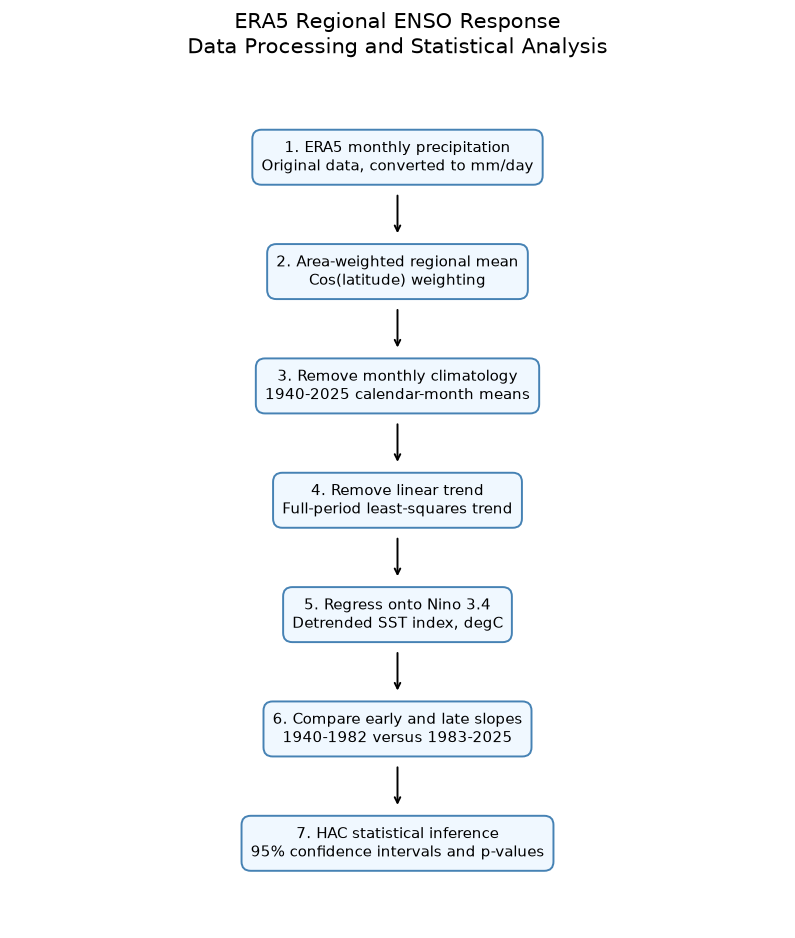

Nino 3.4 index loaded: 1032 months
ERA5 REGIONAL ENSO PRECIPITATION RESPONSE

Western Pacific
Linear trend: 0.0430 mm/day per decade


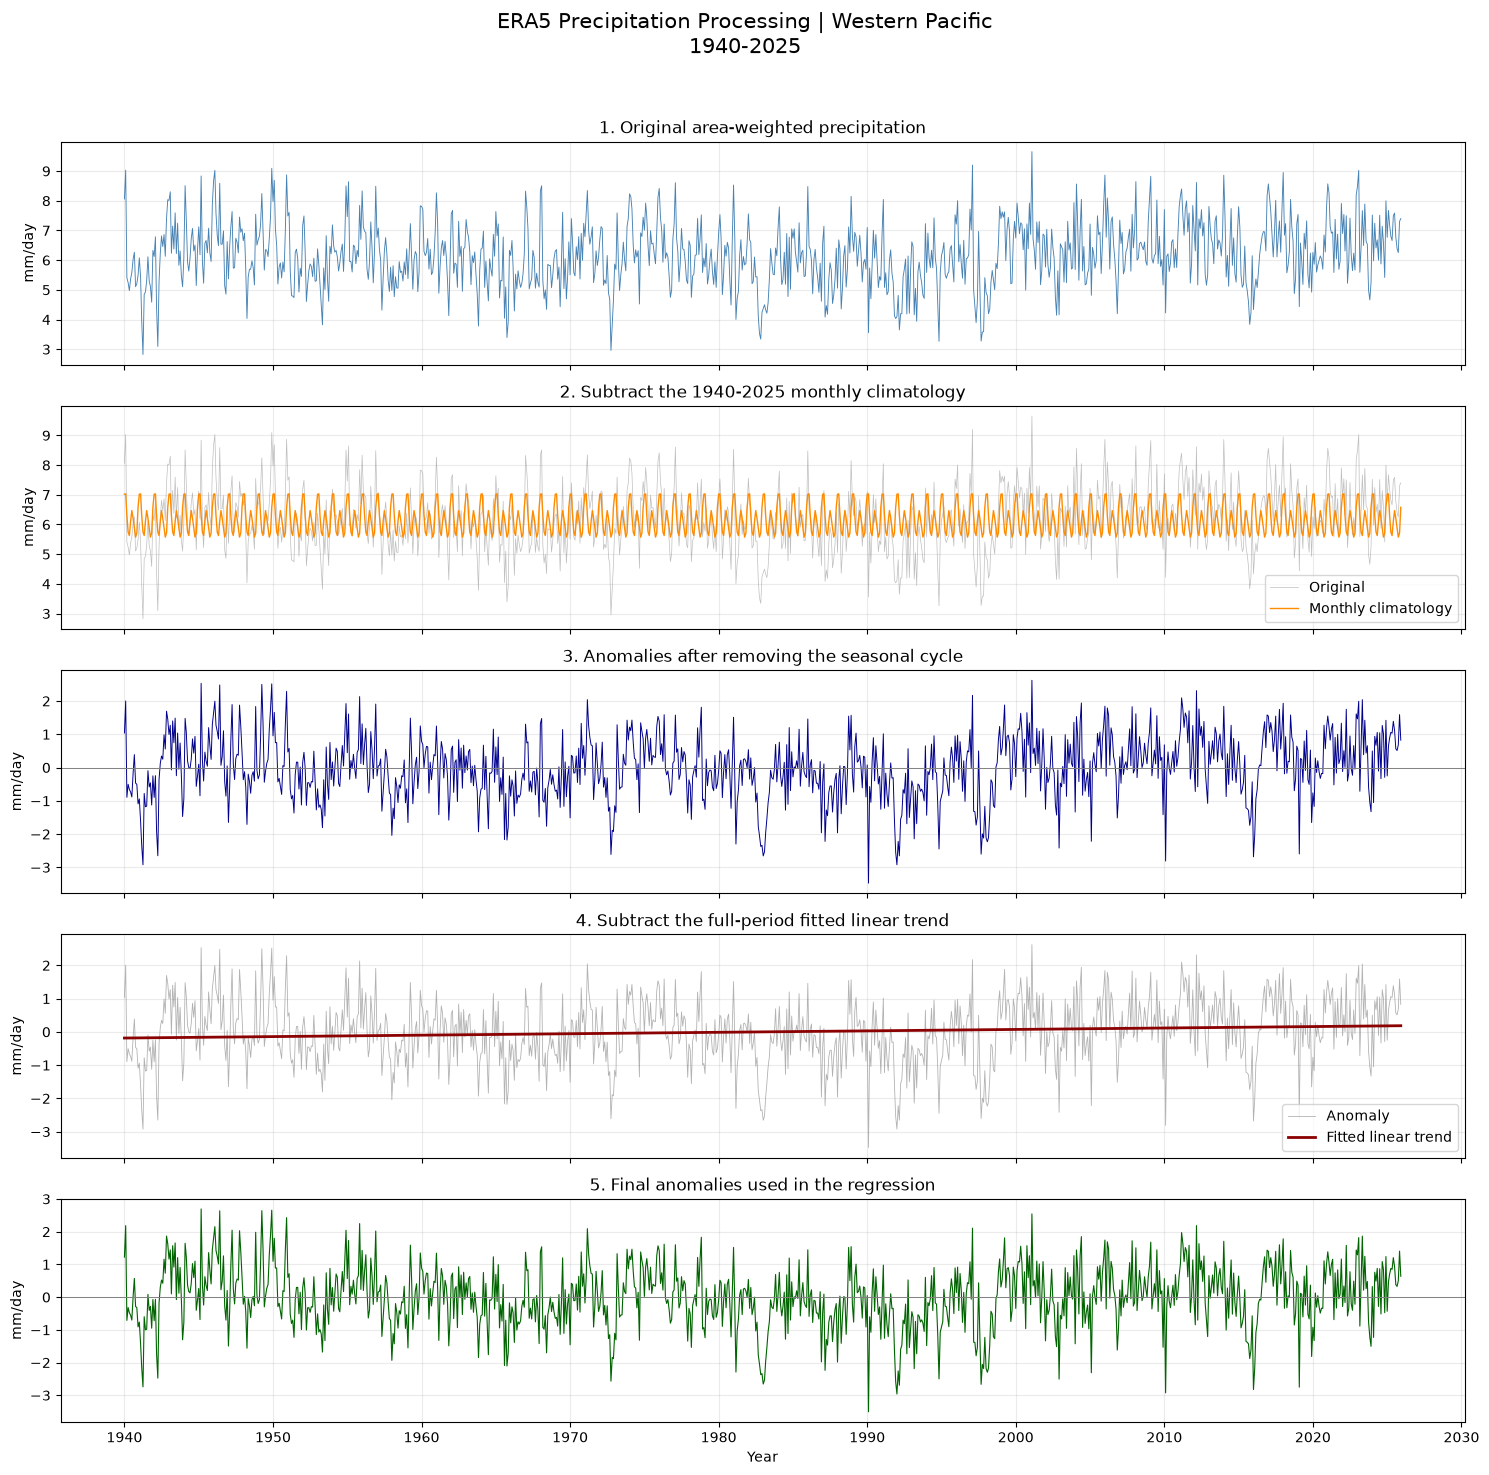

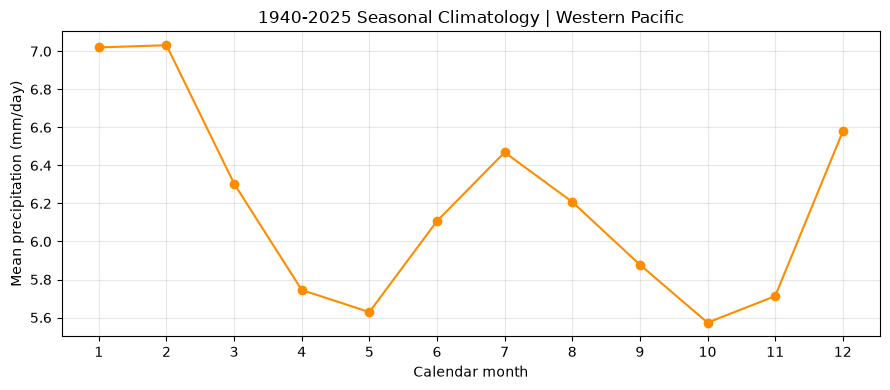

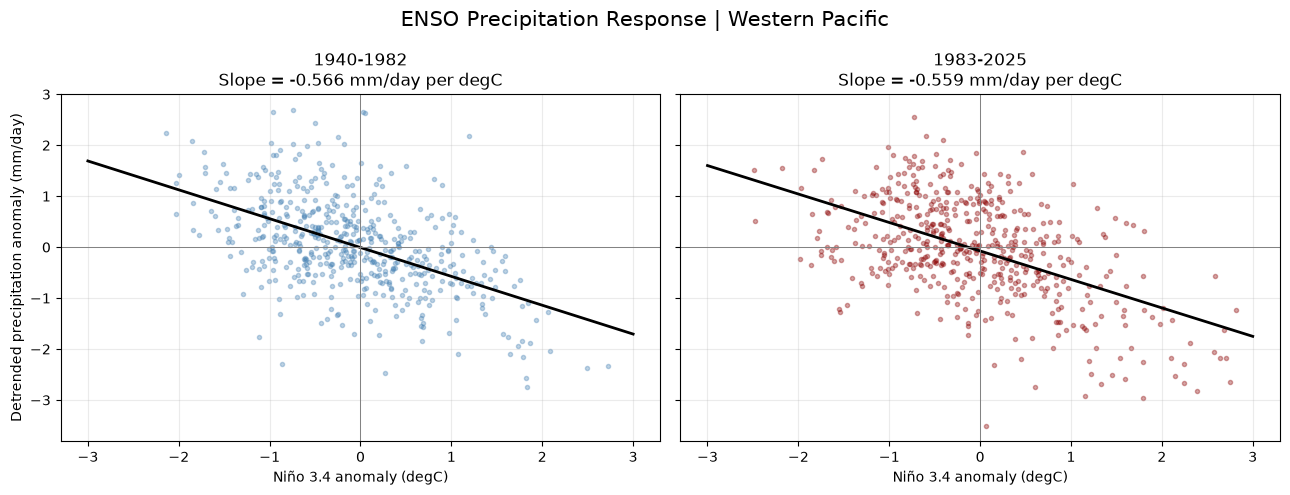


Central Pacific
Linear trend: 0.0012 mm/day per decade


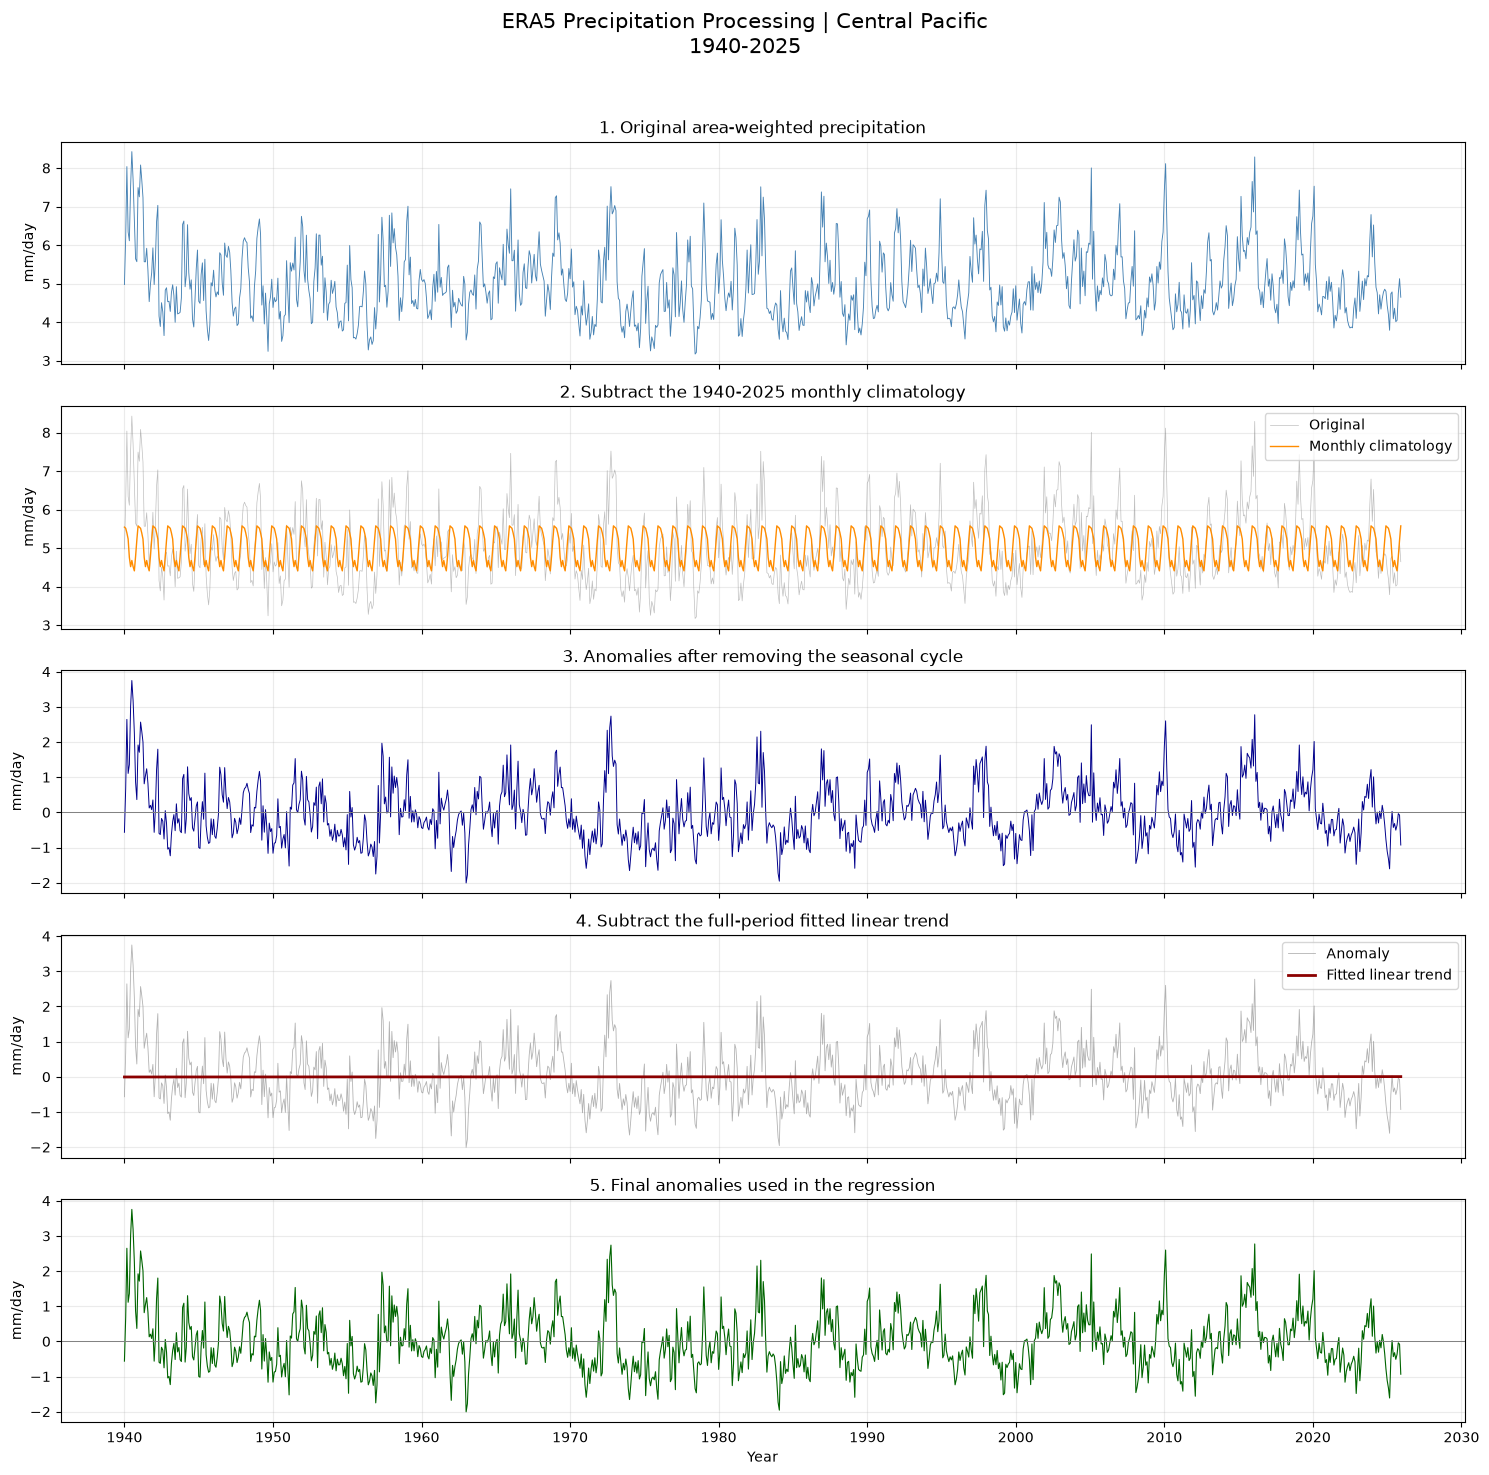

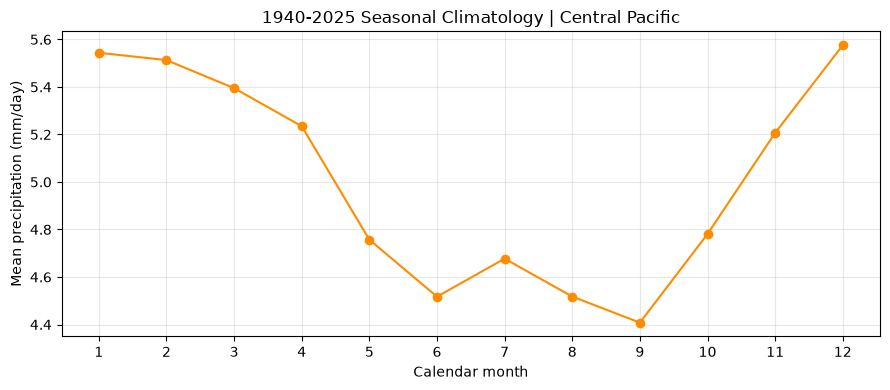

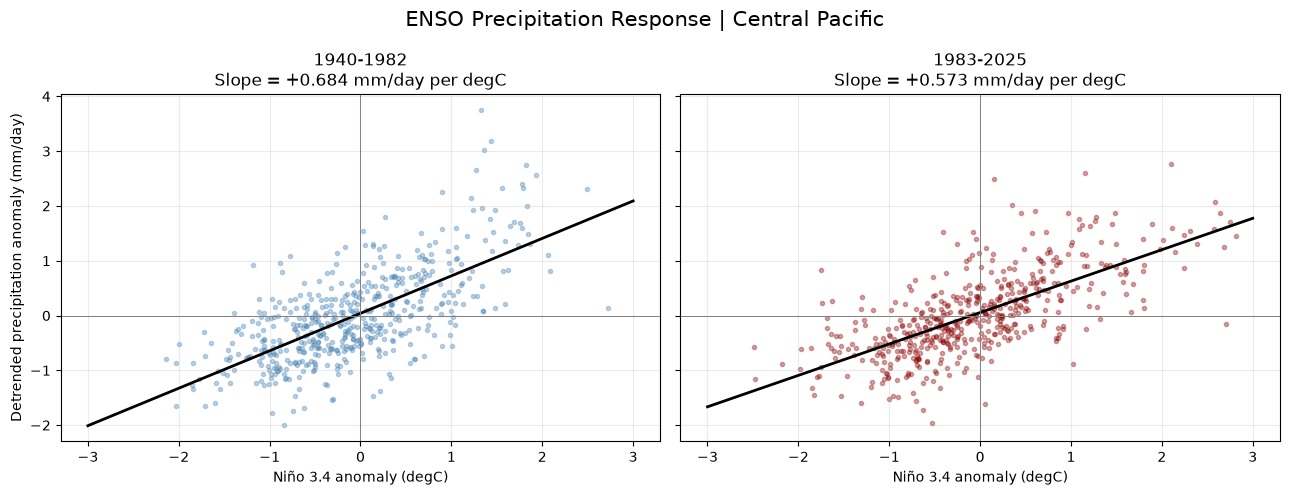


Eastern Pacific
Linear trend: 0.0195 mm/day per decade


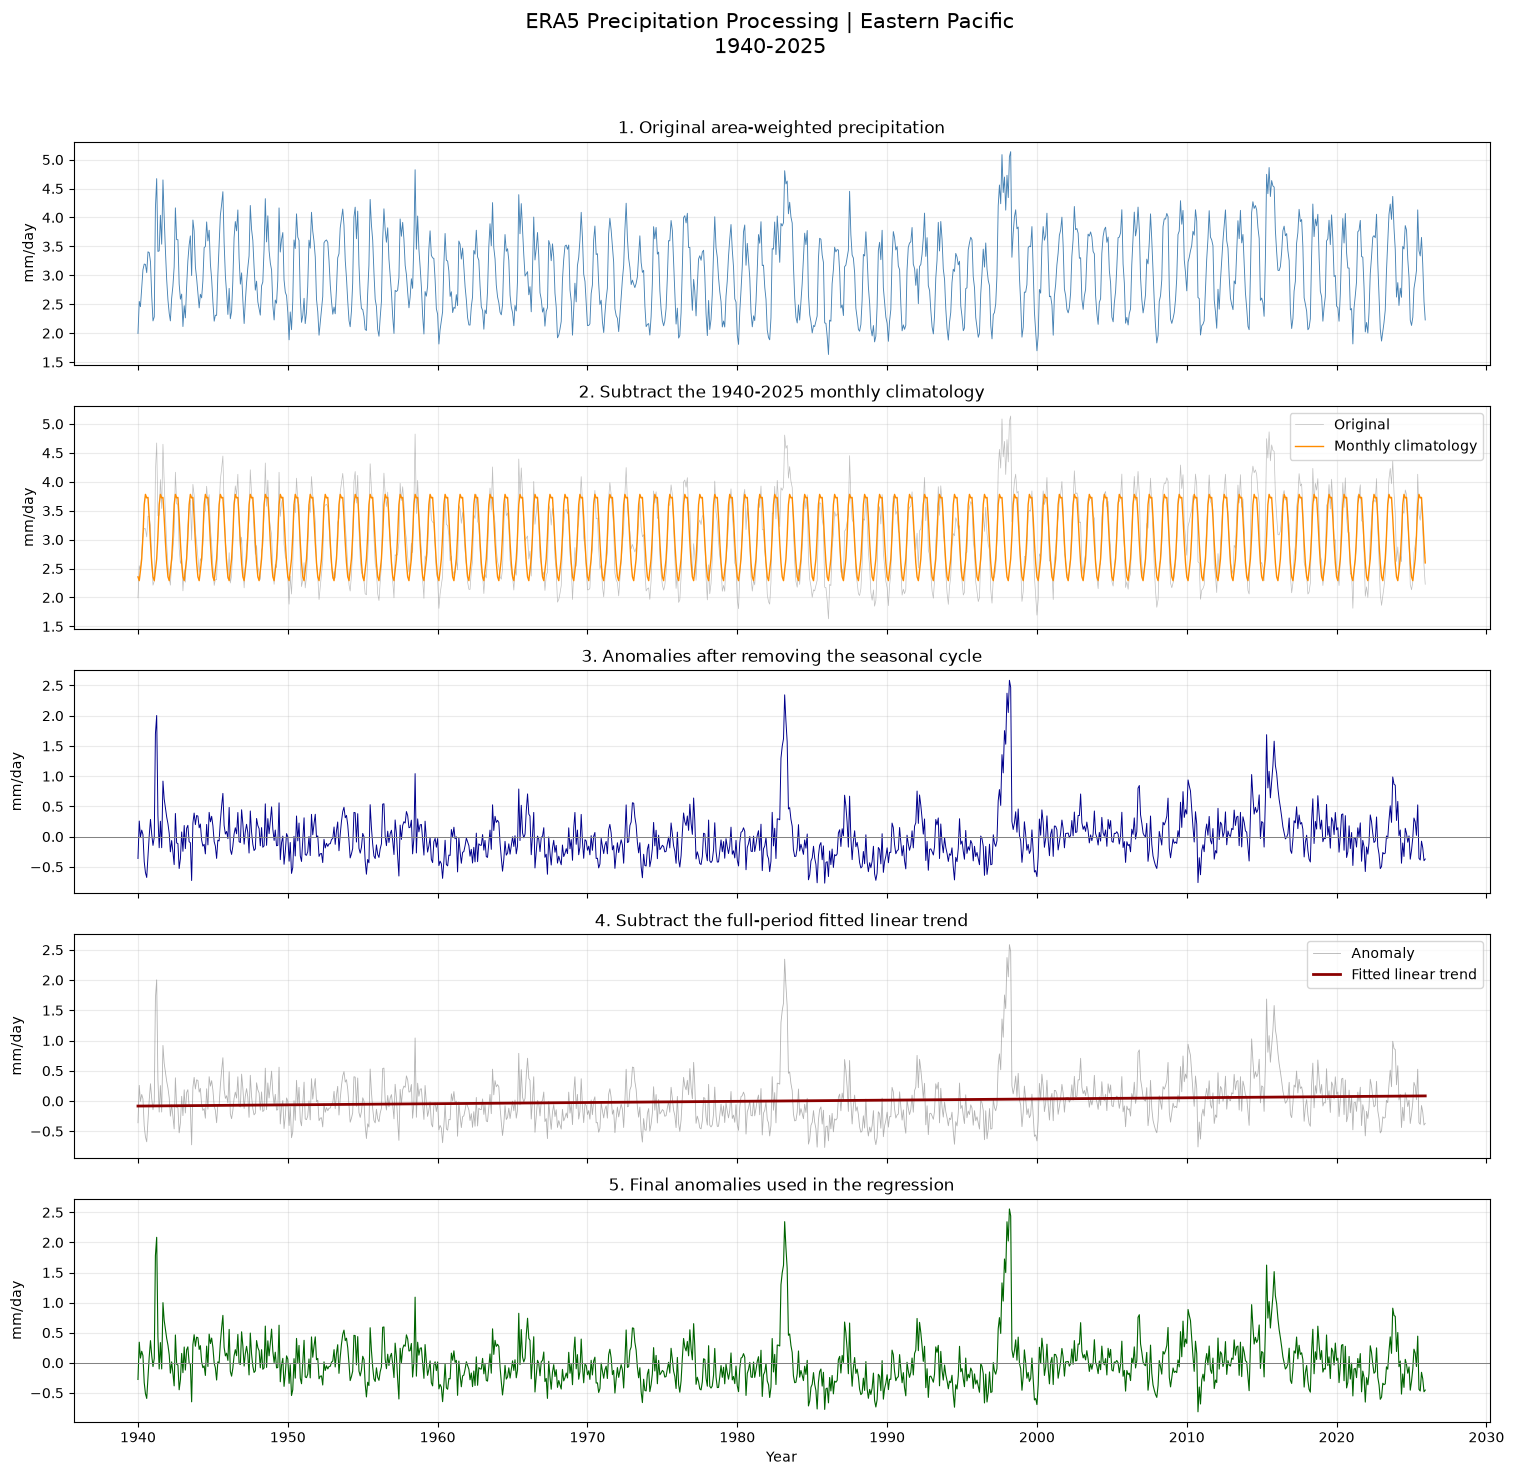

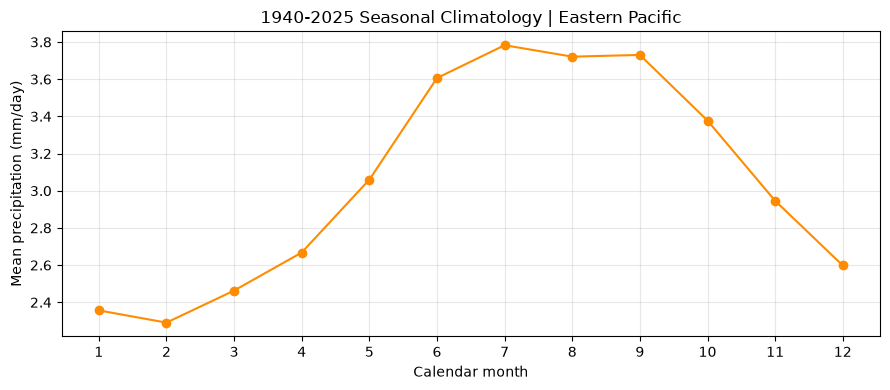

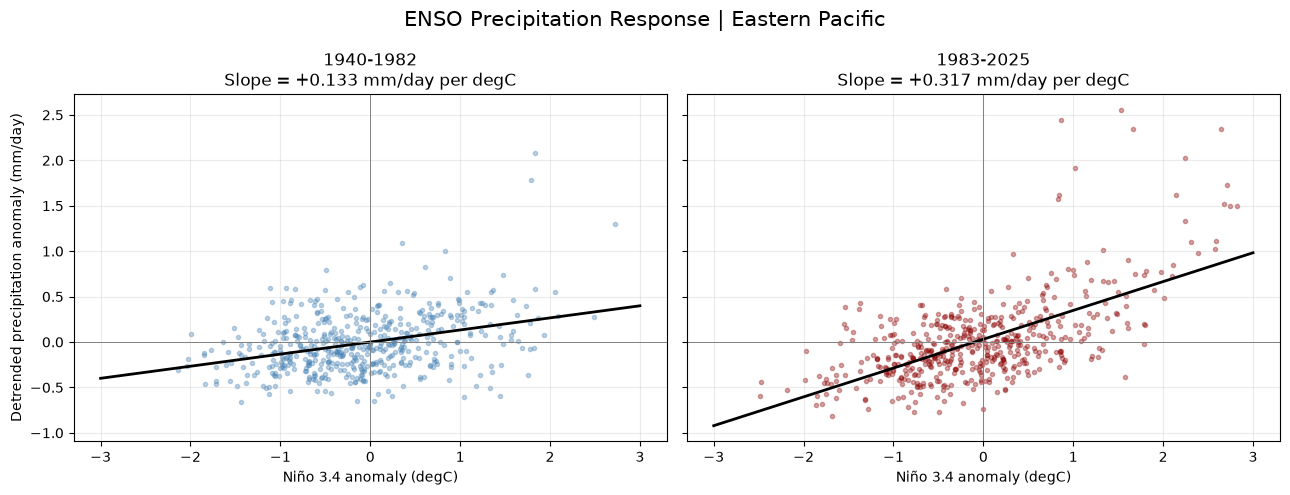


REGIONAL ENSO RESPONSE RESULTS
         Region  Early slope  Late slope  Difference  Difference CI lower  Difference CI upper  p value
Western Pacific      -0.5662     -0.5586      0.0076              -0.1353               0.1505   0.9174
Central Pacific       0.6836      0.5734     -0.1102              -0.2473               0.0268   0.1150
Eastern Pacific       0.1330      0.3173      0.1843               0.0852               0.2833   0.0003


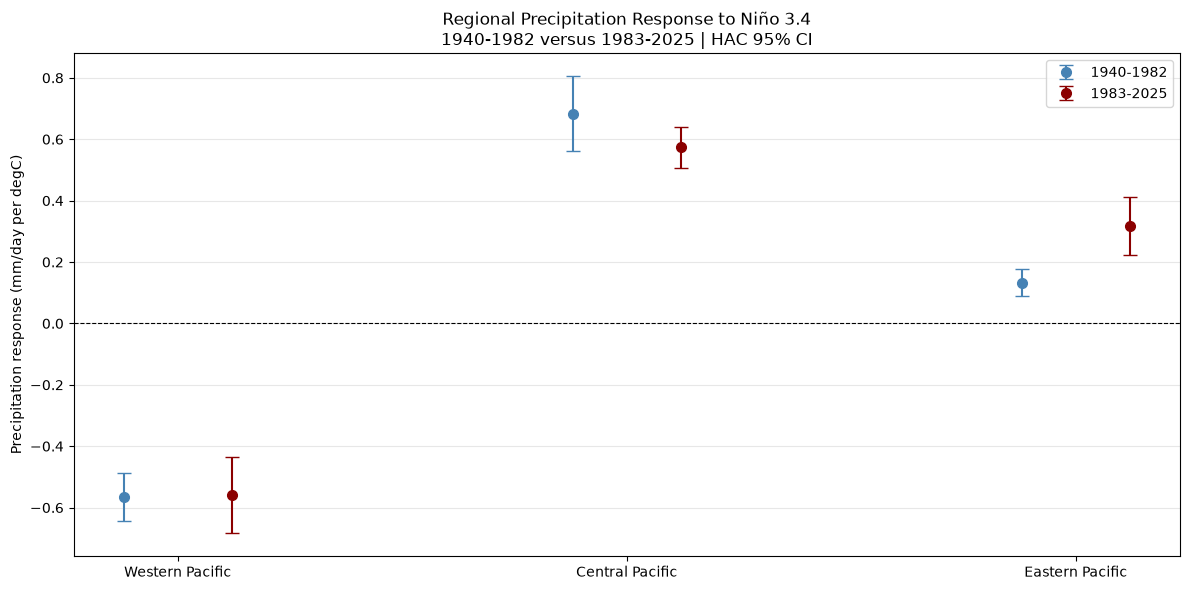

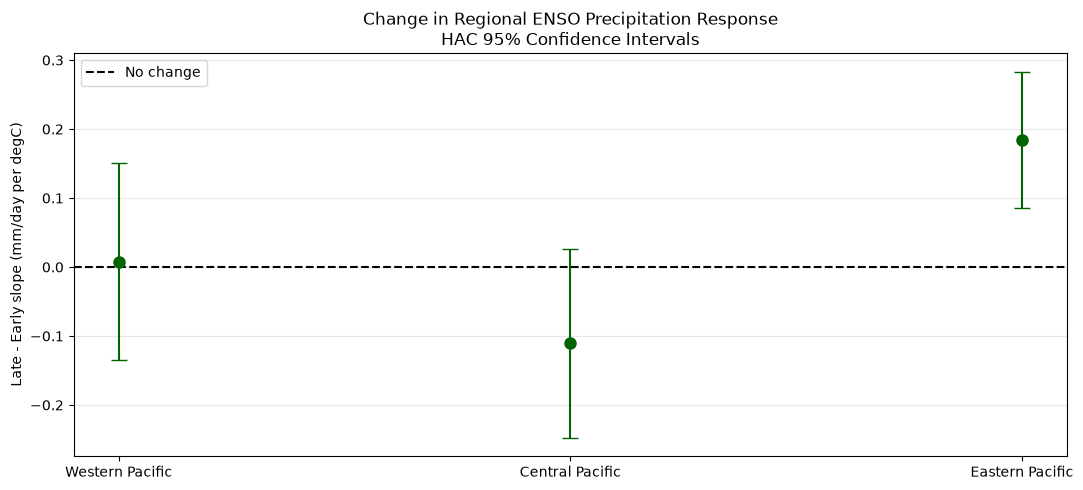


REGIONAL PRECIPITATION ANALYSIS COMPLETE

Western Pacific
  Early slope: -0.5662
  Late slope:  -0.5586
  Difference:  +0.0076
  95% CI: [-0.1353, +0.1505]
  p-value: 0.9174
  No significant change detected

Central Pacific
  Early slope: +0.6836
  Late slope:  +0.5734
  Difference:  -0.1102
  95% CI: [-0.2473, +0.0268]
  p-value: 0.1150
  No significant change detected

Eastern Pacific
  Early slope: +0.1330
  Late slope:  +0.3173
  Difference:  +0.1843
  95% CI: [+0.0852, +0.2833]
  p-value: 0.0003
  Significant change (unadjusted 5%)

Data outputs:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\regional_precipitation_response

Figures:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_regional_precipitation_response


In [15]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path
import statsmodels.api as sm

# ============================================================
# ERA5 REGIONAL ENSO PRECIPITATION RESPONSE
# Western, Central, Eastern Equatorial Pacific
# 1940-2025 | Early/late interaction regression
#
# Outputs:
# 1. Data-processing flowchart
# 2. Processing diagnostics for each region
# 3. Early/late regression scatterplots
# 4. Regression slope comparison with HAC 95% CIs
# 5. CSV files with processed series and results
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_END = 1982
LATE_START = 1983

HAC_LAGS = 36
ALPHA = 0.05

DATA_DIR = Path("data/era5/era5_global")

TP_FILE = DATA_DIR / (
    "era5_total_precipitation_1940_2025.nc"
)

INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

OUTPUT_DIR = Path(
    "derived_data/era5/regional_precipitation_response"
)

FIG_DIR = Path(
    "figures/era5_regional_precipitation_response"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

REGIONS = {
    "Western Pacific": {
        "latitude": (-20, 20),
        "longitude": (120, 160),
    },
    "Central Pacific": {
        "latitude": (-20, 20),
        "longitude": (160, 220),
    },
    "Eastern Pacific": {
        "latitude": (-20, 20),
        "longitude": (220, 280),
    },
}

# ============================================================
# 1. CREATE PROCESSING FLOWCHART
# ============================================================

def plot_processing_flowchart():

    steps = [
        (
            "1. ERA5 monthly precipitation",
            "Original data, converted to mm/day"
        ),
        (
            "2. Area-weighted regional mean",
            "Cos(latitude) weighting"
        ),
        (
            "3. Remove monthly climatology",
            "1940-2025 calendar-month means"
        ),
        (
            "4. Remove linear trend",
            "Full-period least-squares trend"
        ),
        (
            "5. Regress onto Nino 3.4",
            "Detrended SST index, degC"
        ),
        (
            "6. Compare early and late slopes",
            "1940-1982 versus 1983-2025"
        ),
        (
            "7. HAC statistical inference",
            "95% confidence intervals and p-values"
        ),
    ]

    fig, ax = plt.subplots(figsize=(10, 11))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis("off")

    y_positions = np.linspace(9.1, 1.0, len(steps))

    for i, ((title, subtitle), y) in enumerate(
        zip(steps, y_positions)
    ):

        ax.text(
            5, y,
            f"{title}\n{subtitle}",
            ha="center",
            va="center",
            fontsize=11,
            bbox=dict(
                boxstyle="round,pad=0.6",
                facecolor="aliceblue",
                edgecolor="steelblue",
                linewidth=1.4
            )
        )

        if i < len(steps) - 1:
            next_y = y_positions[i + 1]

            ax.annotate(
                "",
                xy=(5, next_y + 0.42),
                xytext=(5, y - 0.42),
                arrowprops=dict(
                    arrowstyle="->",
                    color="black",
                    lw=1.4
                )
            )

    ax.set_title(
        "ERA5 Regional ENSO Response\n"
        "Data Processing and Statistical Analysis",
        fontsize=15,
        pad=20
    )

    plt.savefig(
        FIG_DIR / "analysis_flowchart.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


plot_processing_flowchart()

# ============================================================
# 2. LOAD DETRENDED NINO 3.4
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds:

    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M"),
    name="Nino34"
).sort_index()

expected_months = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert nino_series.index.equals(expected_months)
assert np.isfinite(nino_series.values).all()

print("Nino 3.4 index loaded:", len(nino_series), "months")

# ============================================================
# 3. LOAD REGIONAL PRECIPITATION
# ============================================================

def load_regional_precipitation(ds, region):

    lat_min, lat_max = region["latitude"]
    lon_min, lon_max = region["longitude"]

    da = ds["tp"]

    units = da.attrs.get("units", "").strip()

    # Normalise longitude convention
    da = da.assign_coords(
        longitude=da.longitude % 360
    ).sortby("longitude").sortby("latitude")

    # Select region at native 0.25-degree resolution
    da = da.sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        ),
        latitude=slice(lat_min, lat_max),
        longitude=slice(lon_min, lon_max)
    )

    if da.sizes["latitude"] == 0 or da.sizes["longitude"] == 0:
        raise ValueError("Empty geographical selection")

    # ERA5 monthly averaged daily-mean accumulation
    if units in ("m", "m/day", "m day-1"):
        da = da * 1000.0
    elif units not in ("mm/day", "mm day-1"):
        raise ValueError(
            f"Unexpected precipitation units: {units}"
        )

    # Latitude-area weights, normalised by xarray
    weights = xr.DataArray(
        np.cos(np.deg2rad(da.latitude.values)),
        coords={"latitude": da.latitude},
        dims=["latitude"]
    )

    regional_mean = da.weighted(weights).mean(
        dim=["latitude", "longitude"]
    ).compute()

    months = pd.to_datetime(
        regional_mean.time.values
    ).to_period("M")

    assert months.equals(expected_months), (
        "Regional precipitation months do not match"
    )

    series = pd.Series(
        regional_mean.values,
        index=months,
        name="Precipitation"
    )

    assert np.isfinite(series.values).all()

    return series


# ============================================================
# 4. REMOVE SEASONAL CYCLE AND LINEAR TREND
# ============================================================

def preprocess_precipitation(raw):

    # Full-period calendar-month climatology
    monthly_climatology = raw.groupby(
        raw.index.month
    ).mean()

    seasonal_cycle = pd.Series(
        raw.index.month.map(monthly_climatology).to_numpy(),
        index=raw.index
    )

    # Remove monthly climatology
    anomalies = raw - seasonal_cycle

    # Fit full-period linear trend to anomalies
    t = np.arange(len(anomalies), dtype=float)

    trend_coefficients = np.polyfit(
        t,
        anomalies.values,
        deg=1
    )

    fitted_trend = pd.Series(
        np.polyval(trend_coefficients, t),
        index=raw.index
    )

    # Remove trend
    detrended = anomalies - fitted_trend

    result = pd.DataFrame({
        "Raw": raw,
        "Seasonal climatology": seasonal_cycle,
        "Anomaly": anomalies,
        "Fitted trend": fitted_trend,
        "Detrended anomaly": detrended,
        "Nino34": nino_series
    })

    print(
        "Linear trend:",
        f"{trend_coefficients[0] * 120:.4f} "
        "mm/day per decade"
    )

    return result, monthly_climatology


# ============================================================
# 5. PLOT ACTUAL PROCESSING DIAGNOSTICS
# ============================================================

def plot_processing_diagnostics(
    processed,
    climatology,
    region_name
):

    dates = processed.index.to_timestamp()

    fig, axes = plt.subplots(
        5, 1,
        figsize=(15, 15),
        sharex=True
    )

    # Stage 1: raw precipitation
    axes[0].plot(
        dates,
        processed["Raw"],
        color="steelblue",
        linewidth=0.65
    )

    axes[0].set_title(
        "1. Original area-weighted precipitation"
    )
    axes[0].set_ylabel("mm/day")

    # Stage 2: show the climatology being removed
    axes[1].plot(
        dates,
        processed["Raw"],
        color="grey",
        linewidth=0.5,
        alpha=0.5,
        label="Original"
    )

    axes[1].plot(
        dates,
        processed["Seasonal climatology"],
        color="darkorange",
        linewidth=1,
        label="Monthly climatology"
    )

    axes[1].set_title(
        "2. Subtract the 1940-2025 monthly climatology"
    )
    axes[1].set_ylabel("mm/day")
    axes[1].legend()

    # Stage 3: seasonal anomalies
    axes[2].plot(
        dates,
        processed["Anomaly"],
        color="darkblue",
        linewidth=0.7
    )

    axes[2].axhline(0, color="grey", linewidth=0.7)

    axes[2].set_title(
        "3. Anomalies after removing the seasonal cycle"
    )
    axes[2].set_ylabel("mm/day")

    # Stage 4: fitted trend
    axes[3].plot(
        dates,
        processed["Anomaly"],
        color="grey",
        linewidth=0.6,
        alpha=0.6,
        label="Anomaly"
    )

    axes[3].plot(
        dates,
        processed["Fitted trend"],
        color="darkred",
        linewidth=2,
        label="Fitted linear trend"
    )

    axes[3].set_title(
        "4. Subtract the full-period fitted linear trend"
    )
    axes[3].set_ylabel("mm/day")
    axes[3].legend()

    # Stage 5: final detrended anomalies
    axes[4].plot(
        dates,
        processed["Detrended anomaly"],
        color="darkgreen",
        linewidth=0.8
    )

    axes[4].axhline(0, color="grey", linewidth=0.7)

    axes[4].set_title(
        "5. Final anomalies used in the regression"
    )
    axes[4].set_ylabel("mm/day")
    axes[4].set_xlabel("Year")

    for ax in axes:
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"ERA5 Precipitation Processing | {region_name}\n"
        "1940-2025",
        fontsize=15
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    filename = (
        region_name.lower().replace(" ", "_")
        + "_processing_diagnostics.png"
    )

    plt.savefig(
        FIG_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    # Separate annual-cycle diagnostic
    fig, ax = plt.subplots(figsize=(9, 4))

    ax.plot(
        np.arange(1, 13),
        climatology.values,
        marker="o",
        color="darkorange"
    )

    ax.set_xticks(np.arange(1, 13))
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Mean precipitation (mm/day)")
    ax.set_title(
        f"1940-2025 Seasonal Climatology | {region_name}"
    )
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / (
            region_name.lower().replace(" ", "_")
            + "_monthly_climatology.png"
        ),
        dpi=200
    )

    plt.show()


# ============================================================
# 6. REGRESSION WITH EARLY/LATE INTERACTION
# ============================================================

def fit_response_model(processed):

    years = processed.index.year.to_numpy()

    N = processed["Nino34"].to_numpy()
    Y = processed["Detrended anomaly"].to_numpy()

    D = (years >= LATE_START).astype(float)

    # Model:
    # Y = a + b*N + c*D + d*(N*D) + error
    #
    # b     = early-period response
    # b + d = late-period response
    # d     = late - early response

    design = np.column_stack([
        np.ones(len(N)),
        N,
        D,
        N * D
    ])

    model = sm.OLS(
        Y,
        design
    ).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": HAC_LAGS
        }
    )

    coefficients = model.params
    covariance = np.asarray(model.cov_params())

    early_slope = coefficients[1]
    late_slope = coefficients[1] + coefficients[3]
    difference = coefficients[3]

    # Standard errors from covariance matrix
    early_se = np.sqrt(covariance[1, 1])

    late_se = np.sqrt(
        covariance[1, 1]
        + covariance[3, 3]
        + 2 * covariance[1, 3]
    )

    difference_se = np.sqrt(
        covariance[3, 3]
    )

    # 95% normal-approximation confidence intervals
    z = 1.959963984540054

    return {
        "model": model,
        "early": early_slope,
        "late": late_slope,
        "difference": difference,
        "early_ci": (
            early_slope - z * early_se,
            early_slope + z * early_se
        ),
        "late_ci": (
            late_slope - z * late_se,
            late_slope + z * late_se
        ),
        "difference_ci": (
            difference - z * difference_se,
            difference + z * difference_se
        ),
        "p_value": model.pvalues[3],
    }


# ============================================================
# 7. PLOT EARLY AND LATE REGRESSION RELATIONSHIPS
# ============================================================

def plot_regression_scatter(
    processed,
    fit,
    region_name
):

    early = processed[
        processed.index.year <= EARLY_END
    ]

    late = processed[
        processed.index.year >= LATE_START
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        sharex=True,
        sharey=True
    )

    for ax, subset, slope, title, color in [
        (
            axes[0], early, fit["early"],
            "1940-1982", "steelblue"
        ),
        (
            axes[1], late, fit["late"],
            "1983-2025", "darkred"
        )
    ]:

        x = subset["Nino34"].to_numpy()
        y = subset["Detrended anomaly"].to_numpy()

        ax.scatter(
            x, y,
            s=9,
            alpha=0.35,
            color=color
        )

        intercept = y.mean() - slope * x.mean()

        xline = np.linspace(
            min(x.min(), -3),
            max(x.max(), 3),
            100
        )

        ax.plot(
            xline,
            intercept + slope * xline,
            color="black",
            linewidth=2
        )

        ax.axhline(0, color="grey", linewidth=0.7)
        ax.axvline(0, color="grey", linewidth=0.7)

        ax.set_title(
            f"{title}\n"
            f"Slope = {slope:+.3f} mm/day per degC"
        )

        ax.set_xlabel("Niño 3.4 anomaly (degC)")
        ax.grid(alpha=0.25)

    axes[0].set_ylabel(
        "Detrended precipitation anomaly (mm/day)"
    )

    fig.suptitle(
        f"ENSO Precipitation Response | {region_name}",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / (
            region_name.lower().replace(" ", "_")
            + "_regression_scatter.png"
        ),
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 8. LOAD AND ANALYSE ALL REGIONS
# ============================================================

print("=" * 70)
print("ERA5 REGIONAL ENSO PRECIPITATION RESPONSE")
print("=" * 70)

processed_data = {}
regression_results = {}
summary_rows = []

with xr.open_dataset(
    TP_FILE,
    engine="netcdf4",
    chunks="auto"
) as ds:

    if "valid_time" in ds.dims:
        ds = ds.rename({"valid_time": "time"})

    for region_name, bounds in REGIONS.items():

        print("\n" + "=" * 60)
        print(region_name)
        print("=" * 60)

        raw = load_regional_precipitation(
            ds, bounds
        )

        processed, climatology = (
            preprocess_precipitation(raw)
        )

        processed_data[region_name] = processed

        # Show each processing stage
        plot_processing_diagnostics(
            processed,
            climatology,
            region_name
        )

        # Statistical regression
        fit = fit_response_model(processed)

        regression_results[region_name] = fit

        # Plot the regression
        plot_regression_scatter(
            processed,
            fit,
            region_name
        )

        summary_rows.append({
            "Region": region_name,
            "Early slope": fit["early"],
            "Late slope": fit["late"],
            "Difference": fit["difference"],
            "Difference CI lower": fit["difference_ci"][0],
            "Difference CI upper": fit["difference_ci"][1],
            "p value": fit["p_value"],
        })

        processed.to_csv(
            OUTPUT_DIR / (
                region_name.lower().replace(" ", "_")
                + "_processed_precipitation.csv"
            )
        )

summary = pd.DataFrame(summary_rows)

summary.to_csv(
    OUTPUT_DIR / "regional_response_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("REGIONAL ENSO RESPONSE RESULTS")
print("=" * 70)

print(summary.round(4).to_string(index=False))

# ============================================================
# 9. PLOT REGIONAL REGRESSION SLOPE COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

region_names = list(REGIONS)

x = np.arange(len(region_names))
offset = 0.12

for shift, period, key, ci_key, color in [
    (
        -offset, "1940-1982",
        "early", "early_ci", "steelblue"
    ),
    (
        offset, "1983-2025",
        "late", "late_ci", "darkred"
    )
]:

    slopes = np.array([
        regression_results[r][key]
        for r in region_names
    ])

    lower = np.array([
        regression_results[r][ci_key][0]
        for r in region_names
    ])

    upper = np.array([
        regression_results[r][ci_key][1]
        for r in region_names
    ])

    ax.errorbar(
        x + shift,
        slopes,
        yerr=[
            slopes - lower,
            upper - slopes
        ],
        fmt="o",
        capsize=5,
        markersize=7,
        label=period,
        color=color
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(region_names)

ax.set_ylabel(
    "Precipitation response (mm/day per degC)"
)

ax.set_title(
    "Regional Precipitation Response to Niño 3.4\n"
    "1940-1982 versus 1983-2025 | HAC 95% CI"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "regional_slope_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. PLOT SLOPE DIFFERENCES AND SIGNIFICANCE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))

differences = np.array([
    regression_results[r]["difference"]
    for r in region_names
])

lower = np.array([
    regression_results[r]["difference_ci"][0]
    for r in region_names
])

upper = np.array([
    regression_results[r]["difference_ci"][1]
    for r in region_names
])

ax.errorbar(
    x,
    differences,
    yerr=[
        differences - lower,
        upper - differences
    ],
    fmt="o",
    capsize=6,
    markersize=8,
    color="darkgreen"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    label="No change"
)

ax.set_xticks(x)
ax.set_xticklabels(region_names)

ax.set_ylabel(
    "Late - Early slope (mm/day per degC)"
)

ax.set_title(
    "Change in Regional ENSO Precipitation Response\n"
    "HAC 95% Confidence Intervals"
)

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "regional_slope_differences.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("REGIONAL PRECIPITATION ANALYSIS COMPLETE")
print("=" * 70)

for region in region_names:

    fit = regression_results[region]

    print(f"\n{region}")
    print(
        f"  Early slope: {fit['early']:+.4f}"
    )
    print(
        f"  Late slope:  {fit['late']:+.4f}"
    )
    print(
        f"  Difference:  {fit['difference']:+.4f}"
    )
    print(
        f"  95% CI: [{fit['difference_ci'][0]:+.4f}, "
        f"{fit['difference_ci'][1]:+.4f}]"
    )
    print(
        f"  p-value: {fit['p_value']:.4f}"
    )

    if fit["p_value"] < ALPHA:
        print("  Significant change (unadjusted 5%)")
    else:
        print("  No significant change detected")

print("\nData outputs:")
print(OUTPUT_DIR.resolve())

print("\nFigures:")
print(FIG_DIR.resolve())

print("=" * 70)
